# 02 — Audit kualitas data SO₂ per stasiun

Acuan: hasil eksekusi `01_audit_data.ipynb` dan `outputs/audit_struktur_data.json`.
Header baris 8, satuan baris 9, awal tabel baris 10 diperiksa ulang untuk tiap sheet.
Kode audit yang dapat ditinjau berada di `scripts/audit_quality.py`.

File sumber hanya dibaca. Grid 30 menit adalah turunan audit, bukan pengganti data mentah.
Tidak ada imputasi, penghapusan outlier, smoothing, scaling, pemilihan stasiun final,
pelatihan model, dugaan zona waktu/kode sensor/penyebab anomali, atau atribusi ke Anak Krakatau.


In [1]:
from pathlib import Path
import sys, os
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT/'data_raw').is_dir()
os.environ.setdefault('MPLCONFIGDIR', str(ROOT/'outputs'/'.mplconfig'))
sys.path.insert(0, str(ROOT/'scripts'))
import pandas as pd
from IPython.display import display, Markdown, Image
from audit_quality import run_audit, export_excel, DEFINITIONS
print('Python:',sys.version)
print('Interpreter:',sys.executable)
display(pd.DataFrame(DEFINITIONS,columns=['Istilah','Definisi']))

Python: 3.15.2 (tags/v3.15.2:5e58eaa, Oct 25 2026, 17:27:03) [MSC v.1951 64 bit (AMD64)]
Interpreter: C:\Users\INTAN\airpollutan_SO2\.venv\Scripts\python.exe


,Istilah,Definisi
0,Sumber,Excel asli pada data_raw; struktur mengacu not...
1,Persen kosong variabel,100 × jumlah sel kosong / seluruh baris tabel ...
2,Grid audit,Slot menit 00/30 dengan detik dan mikrodetik n...
3,Persen SO2 teramati,100 × slot grid dengan sedikitnya satu nilai S...
4,Persen tanpa baris,100 × slot grid tanpa baris sumber / seluruh s...
5,Persen baris ada SO2 kosong,100 × slot grid dengan baris tetapi semua SO2 ...
6,Persen hilang SO2,100 × (slot tanpa baris + slot baris ada semua...
7,Persen bulanan,"Definisi kelengkapan SO2 yang sama, denominato..."
8,Duplikat,Grup berdasarkan timestamp berhasil dibaca; id...
9,Plot dan konstan,Slot numerik hanya jika SO2 semua baris pada t...


## Menjalankan seluruh pemeriksaan

Timestamp dibaca dengan format eksplisit; nilai numerik Excel yang tidak bertipe tanggal
tidak ditebak sebagai timestamp. Semua baris sumber tetap dipertahankan pada analisis per baris.
Duplikat dianalisis sebelum grid dibuat dan tidak dihapus dari data sumber.
Kelengkapan grid menghitung slot dengan sedikitnya satu nilai nonkosong; konflik disajikan terpisah.
Nilai nonnumerik/nonfinite tidak diperlakukan sebagai pengukuran numerik pada statistik/grafik.


In [2]:
tables, results = run_audit()
display(pd.DataFrame(tables['Sumber_SHA256']))
display(pd.DataFrame(tables['Kendala']))

Audit: Bandar Lampung Talang
Audit: Kab. Lampung Selatan Way Urang
Audit: Kota Cilegon Pulomerak
Audit: Kab. Serang Binuang
Audit: Kab. Tangerang Curug
Audit: Tangerang Pasir Jaya
Audit: Tangerang Selatan Serpong
Audit: Serang Sumurpecung


,File sumber,SHA256 sebelum,SHA256 sesudah,Identik selama audit,Identik dengan tahap 1
0,data_raw\Telkom University Purwokerto - Intan ...,bd00734b954e8df024c048575fad07f1eb1cbe1083d4c8...,bd00734b954e8df024c048575fad07f1eb1cbe1083d4c8...,True,True


,Kendala
0,Tidak ada pemeriksaan yang gagal dijalankan.


## Hasil terpisah untuk setiap stasiun

Tabel rentang pemeriksaan berisi hitungan seluruh kejadian; contoh dibatasi 10 per aturan.
Tabel kandidat ekstrem menampilkan minimum dan maksimum, tanpa menyatakan batas sensor.
Semua gap, interval bermasalah, duplikat dan rentetan SO2 tersedia pada workbook keluaran.


## Bandar Lampung Talang

### Ringkasan

,File,Stasiun,Jumlah baris sumber,Timestamp minimum,Timestamp maksimum,Timestamp gagal,Waktu nonmenurun,Waktu meningkat ketat,Pasangan waktu mundur,Grup duplikat identik,Grup duplikat konflik,Baris dalam grup duplikat,Baris duplikat tambahan,Di luar pola 00 atau 30,Pasangan sumber terbaca,Pasangan sumber bukan 30 menit,Interval unik terurut bukan 30 menit,Denominator slot grid,SO2 teramati slot,SO2 teramati persen,Tanpa baris slot,Tanpa baris persen,Baris ada SO2 kosong slot,Baris ada SO2 kosong persen,SO2 hilang slot,SO2 hilang persen,Slot SO2 ambigu,Jumlah gap SO2,Gap terpanjang jam,SO2 nonkosong baris di luar grid
0,Telkom University Purwokerto - Intan Azizah.xlsx,Bandar Lampung Talang,28226,2025-01-01,2026-09-22 11:30:00,0,True,True,0,0,0,0,0,0,28225,29,29,30216,26189,86.672624,1990,6.585915,2037,6.741461,4027,13.327376,0,32,1011.5,0


### Metadata

,File,Stasiun,Periode teks asli,Awal metadata,Akhir metadata,Tanggal aktual minimum,Tanggal aktual maksimum,Awal tanggal sesuai,Akhir tanggal sesuai,Baris di luar tanggal metadata,Keterbatasan
0,Telkom University Purwokerto - Intan Azizah.xlsx,Bandar Lampung Talang,: 01 Januari 2025 - 22 September 2026,2025-01-01,2026-09-22,2025-01-01,2026-09-22,True,True,0,Tanggal tanpa jam; zona waktu dan kode sensor ...


### Kelengkapan variabel

... (21 outputs left out)

### Masalah_waktu: 0 kejadian (maksimal 10 ditampilkan)

""


### Nilai_nonnumerik: 0 kejadian (maksimal 10 ditampilkan)

""


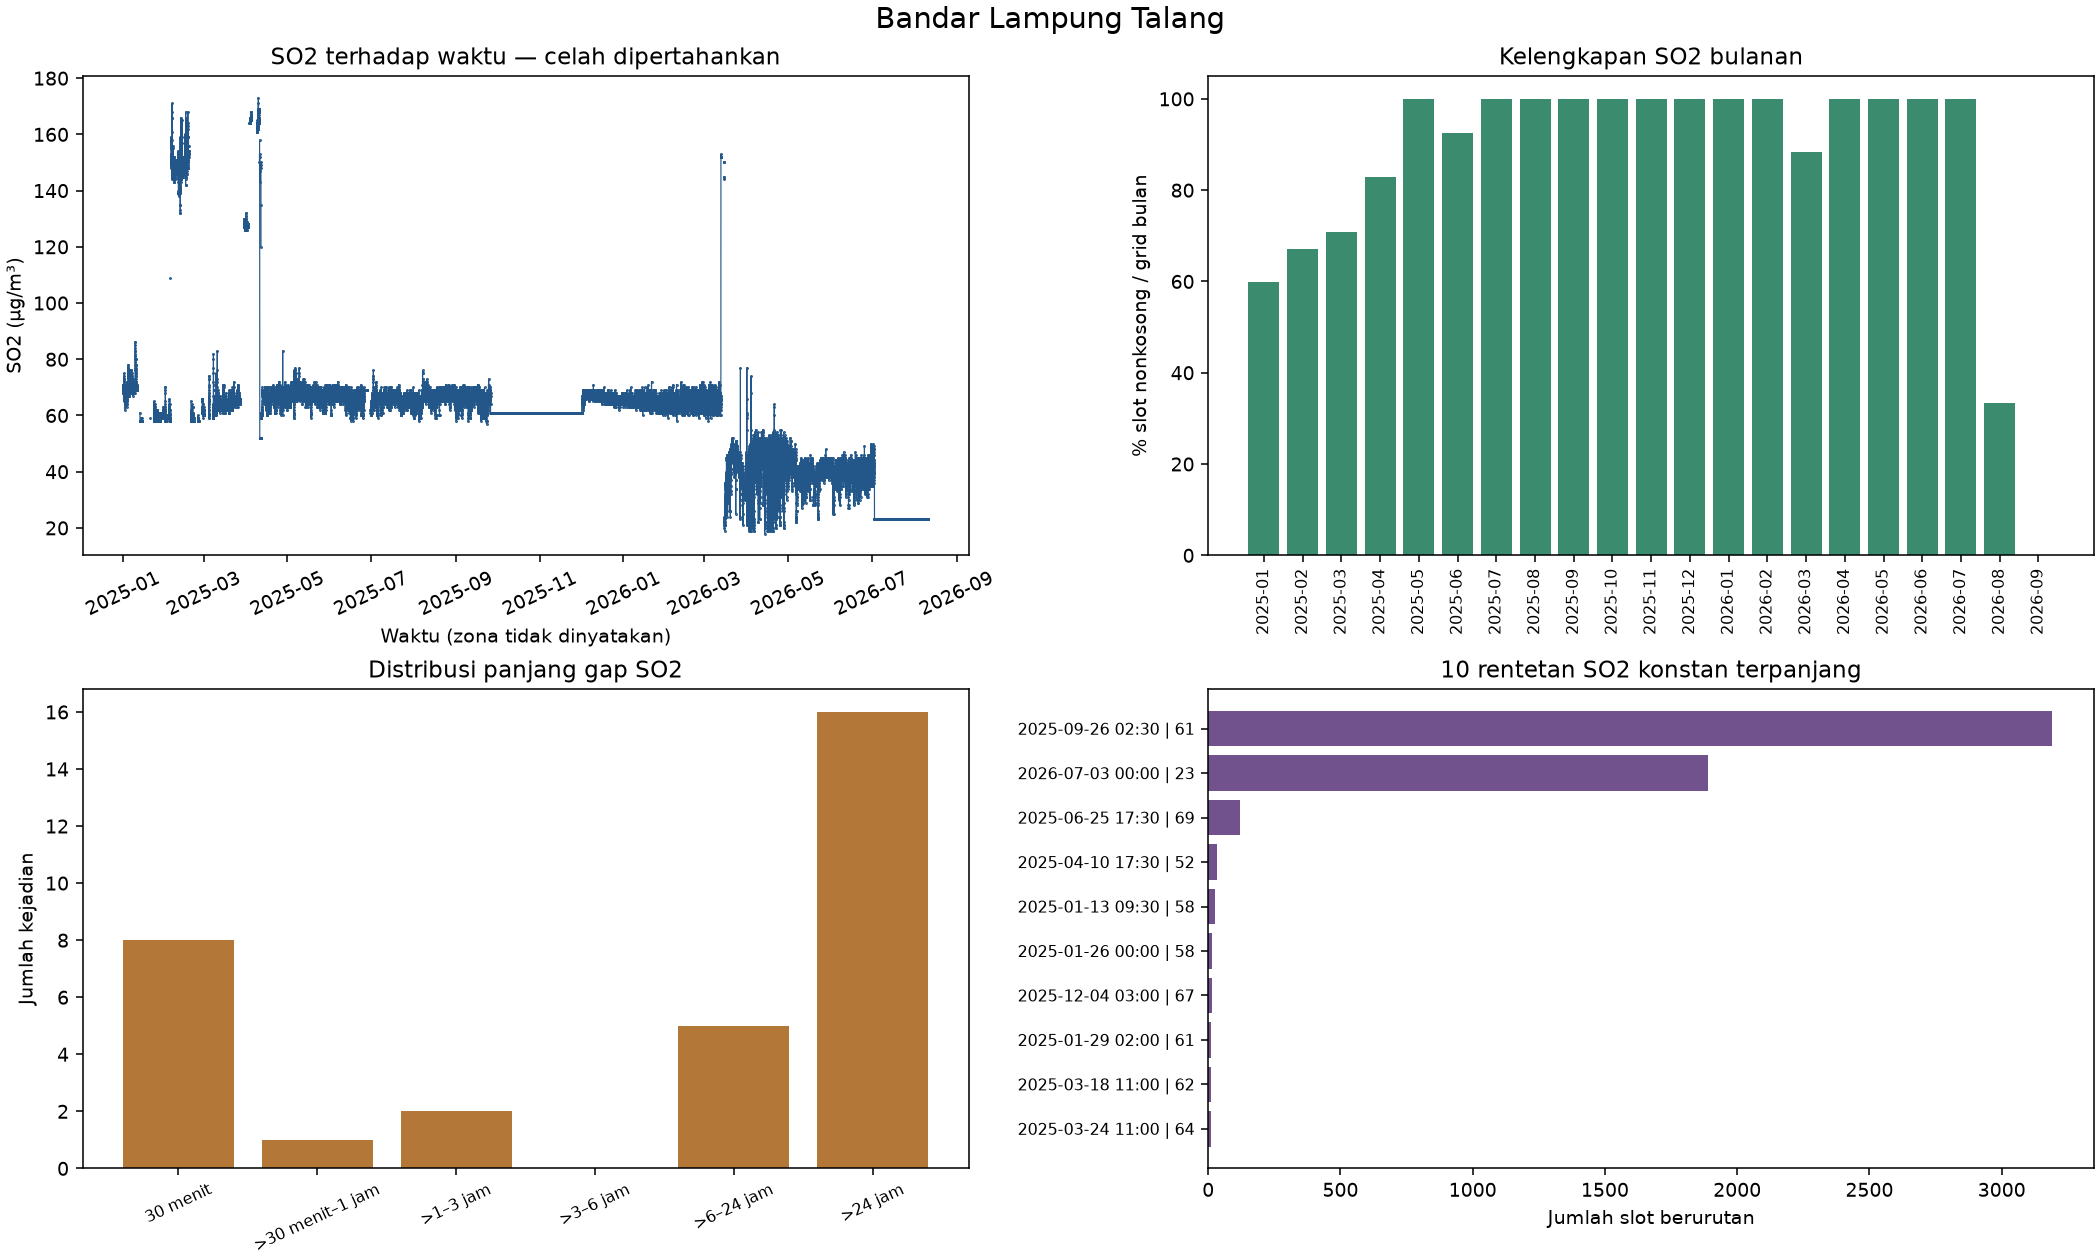

## Kab. Lampung Selatan Way Urang

### Ringkasan

,File,Stasiun,Jumlah baris sumber,Timestamp minimum,Timestamp maksimum,Timestamp gagal,Waktu nonmenurun,Waktu meningkat ketat,Pasangan waktu mundur,Grup duplikat identik,Grup duplikat konflik,Baris dalam grup duplikat,Baris duplikat tambahan,Di luar pola 00 atau 30,Pasangan sumber terbaca,Pasangan sumber bukan 30 menit,Interval unik terurut bukan 30 menit,Denominator slot grid,SO2 teramati slot,SO2 teramati persen,Tanpa baris slot,Tanpa baris persen,Baris ada SO2 kosong slot,Baris ada SO2 kosong persen,SO2 hilang slot,SO2 hilang persen,Slot SO2 ambigu,Jumlah gap SO2,Gap terpanjang jam,SO2 nonkosong baris di luar grid
0,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Lampung Selatan Way Urang,29966,2025-01-01,2026-09-21 13:00:00,0,True,True,0,0,0,0,0,1,29965,22,22,30171,28246,93.619701,206,0.682775,1719,5.697524,1925,6.380299,0,29,490.5,0


### Metadata

,File,Stasiun,Periode teks asli,Awal metadata,Akhir metadata,Tanggal aktual minimum,Tanggal aktual maksimum,Awal tanggal sesuai,Akhir tanggal sesuai,Baris di luar tanggal metadata,Keterbatasan
0,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Lampung Selatan Way Urang,: 01 Januari 2025 - 21 September 2026,2025-01-01,2026-09-21,2025-01-01,2026-09-21,True,True,0,Tanggal tanpa jam; zona waktu dan kode sensor ...


### Kelengkapan variabel

... (21 outputs left out)

### Masalah_waktu: 1 kejadian (maksimal 10 ditampilkan)

,File,Stasiun,Jenis,Baris Excel,Nilai asli
0,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Lampung Selatan Way Urang,di luar menit 00/30 atau detik bukan nol,6624,2025-05-22 19:01:00


### Nilai_nonnumerik: 0 kejadian (maksimal 10 ditampilkan)

""


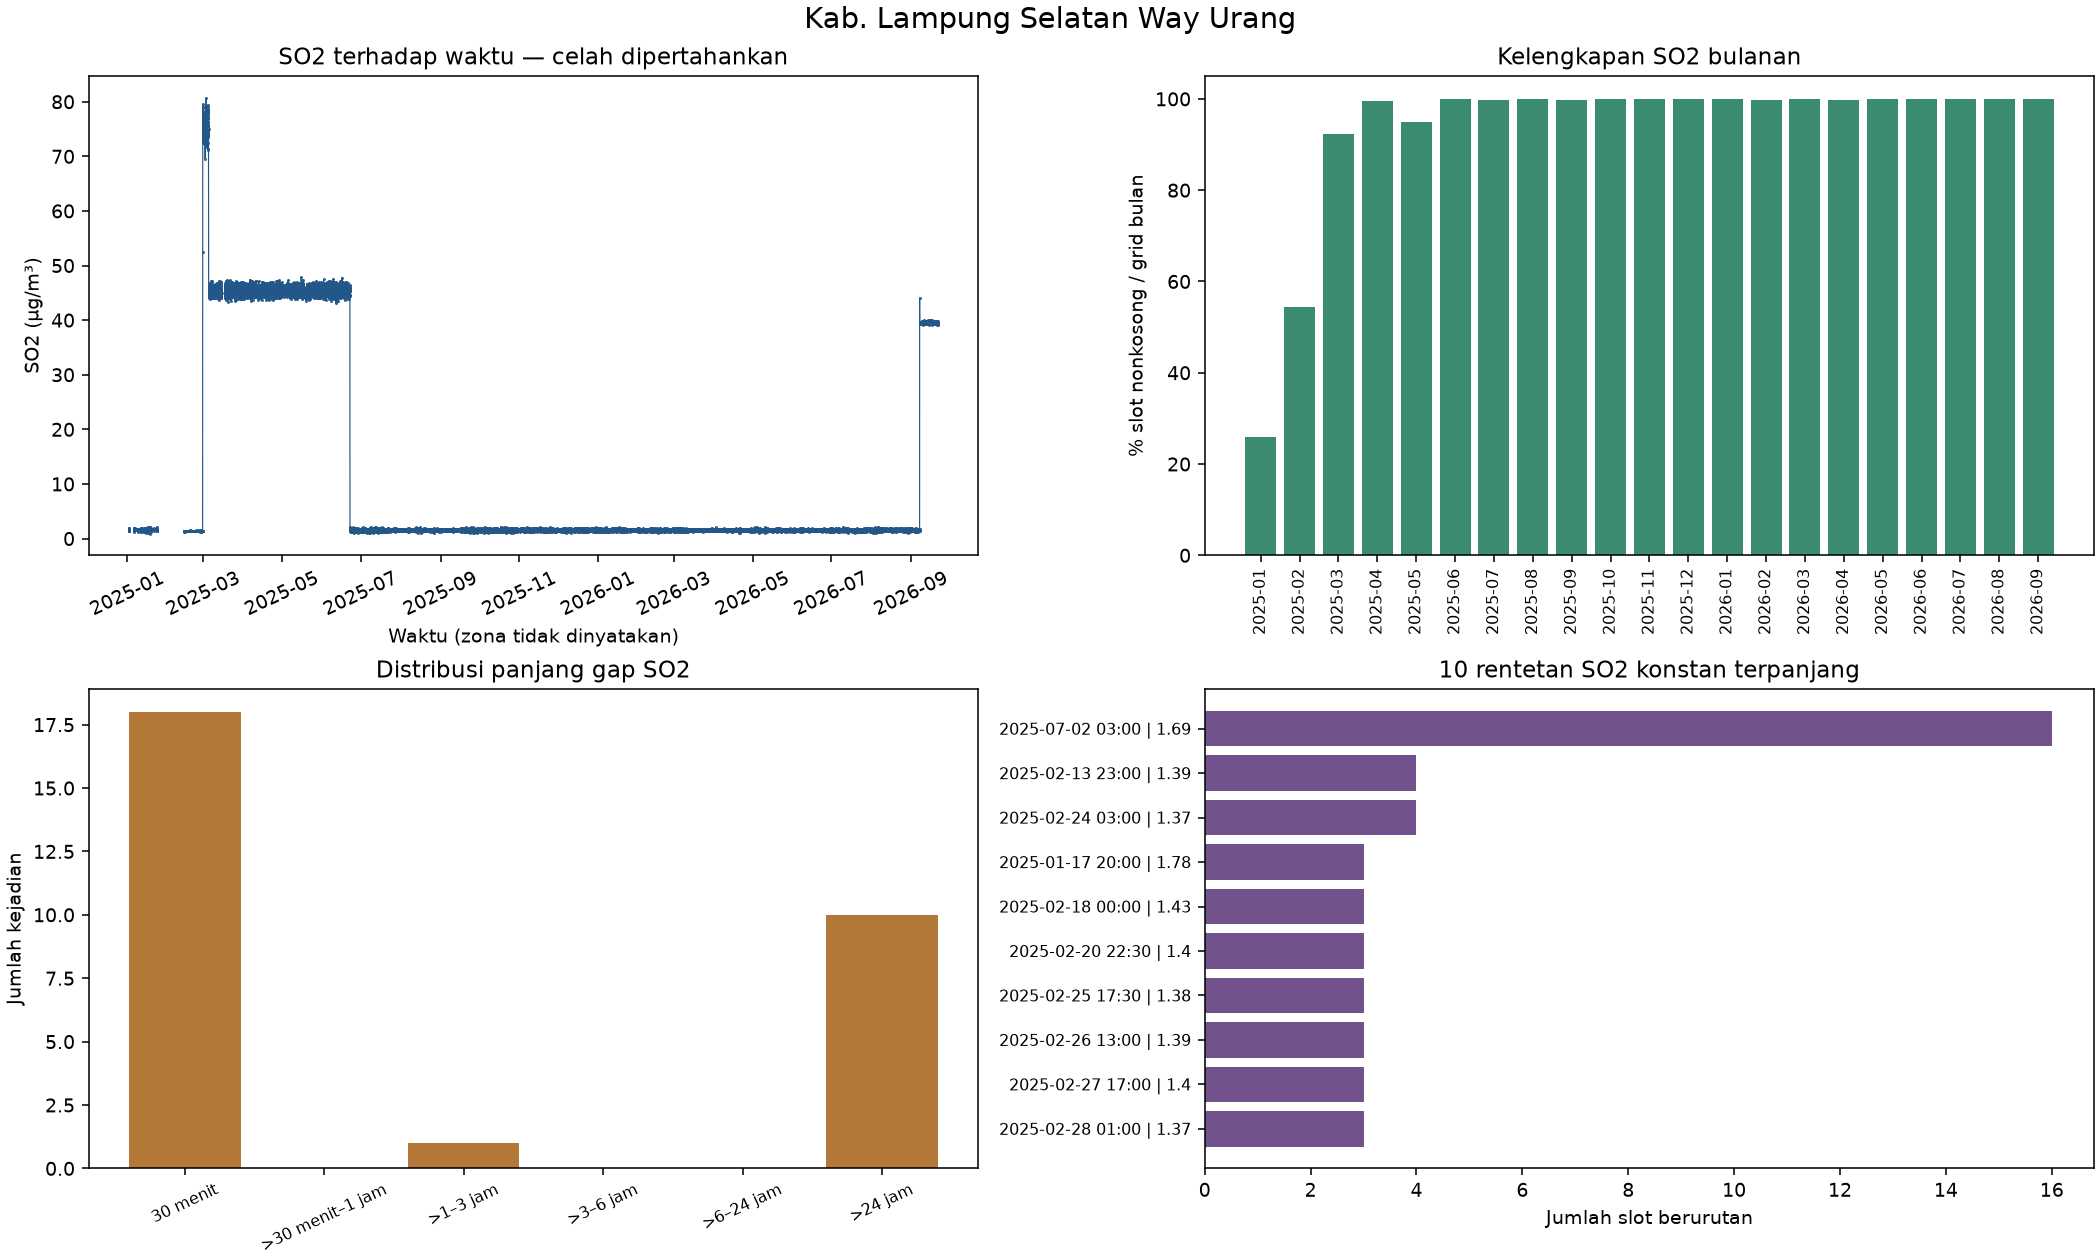

## Kota Cilegon Pulomerak

### Ringkasan

,File,Stasiun,Jumlah baris sumber,Timestamp minimum,Timestamp maksimum,Timestamp gagal,Waktu nonmenurun,Waktu meningkat ketat,Pasangan waktu mundur,Grup duplikat identik,Grup duplikat konflik,Baris dalam grup duplikat,Baris duplikat tambahan,Di luar pola 00 atau 30,Pasangan sumber terbaca,Pasangan sumber bukan 30 menit,Interval unik terurut bukan 30 menit,Denominator slot grid,SO2 teramati slot,SO2 teramati persen,Tanpa baris slot,Tanpa baris persen,Baris ada SO2 kosong slot,Baris ada SO2 kosong persen,SO2 hilang slot,SO2 hilang persen,Slot SO2 ambigu,Jumlah gap SO2,Gap terpanjang jam,SO2 nonkosong baris di luar grid
0,Telkom University Purwokerto - Intan Azizah.xlsx,Kota Cilegon Pulomerak,30399,2025-01-01,2026-09-30 17:30:00,0,True,True,0,0,0,0,0,2,30398,46,46,30612,25439,83.101398,215,0.702339,4958,16.196263,5173,16.898602,0,51,675.0,0


### Metadata

,File,Stasiun,Periode teks asli,Awal metadata,Akhir metadata,Tanggal aktual minimum,Tanggal aktual maksimum,Awal tanggal sesuai,Akhir tanggal sesuai,Baris di luar tanggal metadata,Keterbatasan
0,Telkom University Purwokerto - Intan Azizah.xlsx,Kota Cilegon Pulomerak,: 01 Januari 2025 - 30 September 2026,2025-01-01,2026-09-30,2025-01-01,2026-09-30,True,True,0,Tanggal tanpa jam; zona waktu dan kode sensor ...


### Kelengkapan variabel

... (21 outputs left out)

### Masalah_waktu: 2 kejadian (maksimal 10 ditampilkan)

,File,Stasiun,Jenis,Baris Excel,Nilai asli
0,Telkom University Purwokerto - Intan Azizah.xlsx,Kota Cilegon Pulomerak,di luar menit 00/30 atau detik bukan nol,4394,2025-04-05 12:01:00
1,Telkom University Purwokerto - Intan Azizah.xlsx,Kota Cilegon Pulomerak,di luar menit 00/30 atau detik bukan nol,4396,2025-04-05 14:01:00


### Nilai_nonnumerik: 0 kejadian (maksimal 10 ditampilkan)

""


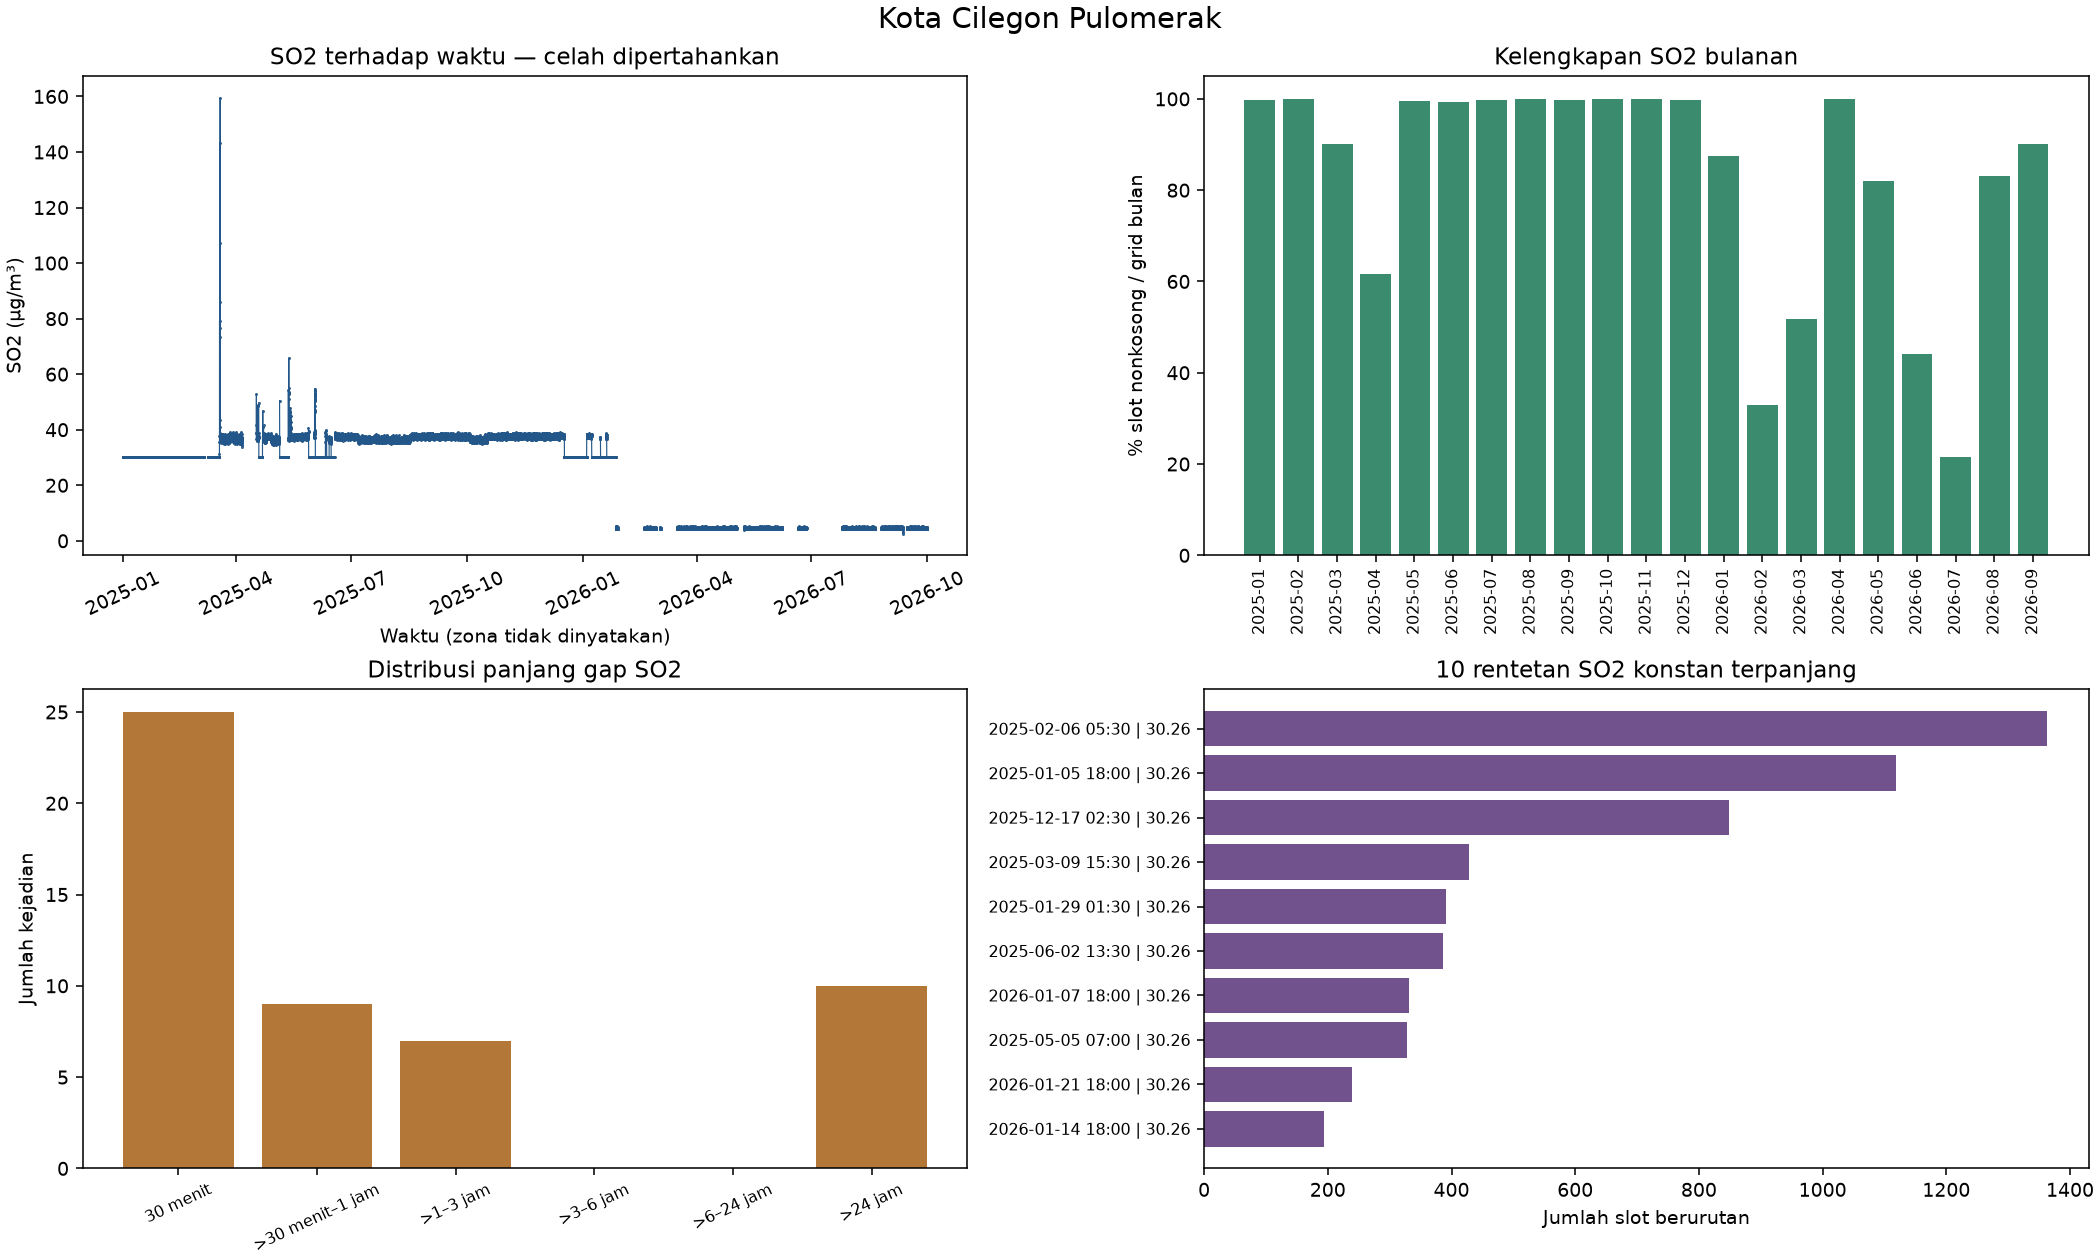

## Kab. Serang Binuang

### Ringkasan

,File,Stasiun,Jumlah baris sumber,Timestamp minimum,Timestamp maksimum,Timestamp gagal,Waktu nonmenurun,Waktu meningkat ketat,Pasangan waktu mundur,Grup duplikat identik,Grup duplikat konflik,Baris dalam grup duplikat,Baris duplikat tambahan,Di luar pola 00 atau 30,Pasangan sumber terbaca,Pasangan sumber bukan 30 menit,Interval unik terurut bukan 30 menit,Denominator slot grid,SO2 teramati slot,SO2 teramati persen,Tanpa baris slot,Tanpa baris persen,Baris ada SO2 kosong slot,Baris ada SO2 kosong persen,SO2 hilang slot,SO2 hilang persen,Slot SO2 ambigu,Jumlah gap SO2,Gap terpanjang jam,SO2 nonkosong baris di luar grid
0,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Serang Binuang,28732,2025-01-01,2026-09-30 17:30:00,0,True,True,0,0,0,0,0,6,28731,60,60,30612,28721,93.822684,1886,6.160983,5,0.016333,1891,6.177316,0,52,331.0,6


### Metadata

,File,Stasiun,Periode teks asli,Awal metadata,Akhir metadata,Tanggal aktual minimum,Tanggal aktual maksimum,Awal tanggal sesuai,Akhir tanggal sesuai,Baris di luar tanggal metadata,Keterbatasan
0,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Serang Binuang,: 01 Januari 2025 - 30 September 2026,2025-01-01,2026-09-30,2025-01-01,2026-09-30,True,True,0,Tanggal tanpa jam; zona waktu dan kode sensor ...


### Kelengkapan variabel

... (21 outputs left out)

### Masalah_waktu: 6 kejadian (maksimal 10 ditampilkan)

,File,Stasiun,Jenis,Baris Excel,Nilai asli
0,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Serang Binuang,di luar menit 00/30 atau detik bukan nol,20007,2026-03-20 20:01:00
1,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Serang Binuang,di luar menit 00/30 atau detik bukan nol,20014,2026-03-21 01:01:00
2,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Serang Binuang,di luar menit 00/30 atau detik bukan nol,27062,2026-08-25 12:01:00
3,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Serang Binuang,di luar menit 00/30 atau detik bukan nol,27342,2026-08-31 08:01:00
4,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Serang Binuang,di luar menit 00/30 atau detik bukan nol,27343,2026-08-31 09:01:00
5,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Serang Binuang,di luar menit 00/30 atau detik bukan nol,28098,2026-09-17 08:01:00


### Nilai_nonnumerik: 0 kejadian (maksimal 10 ditampilkan)

""


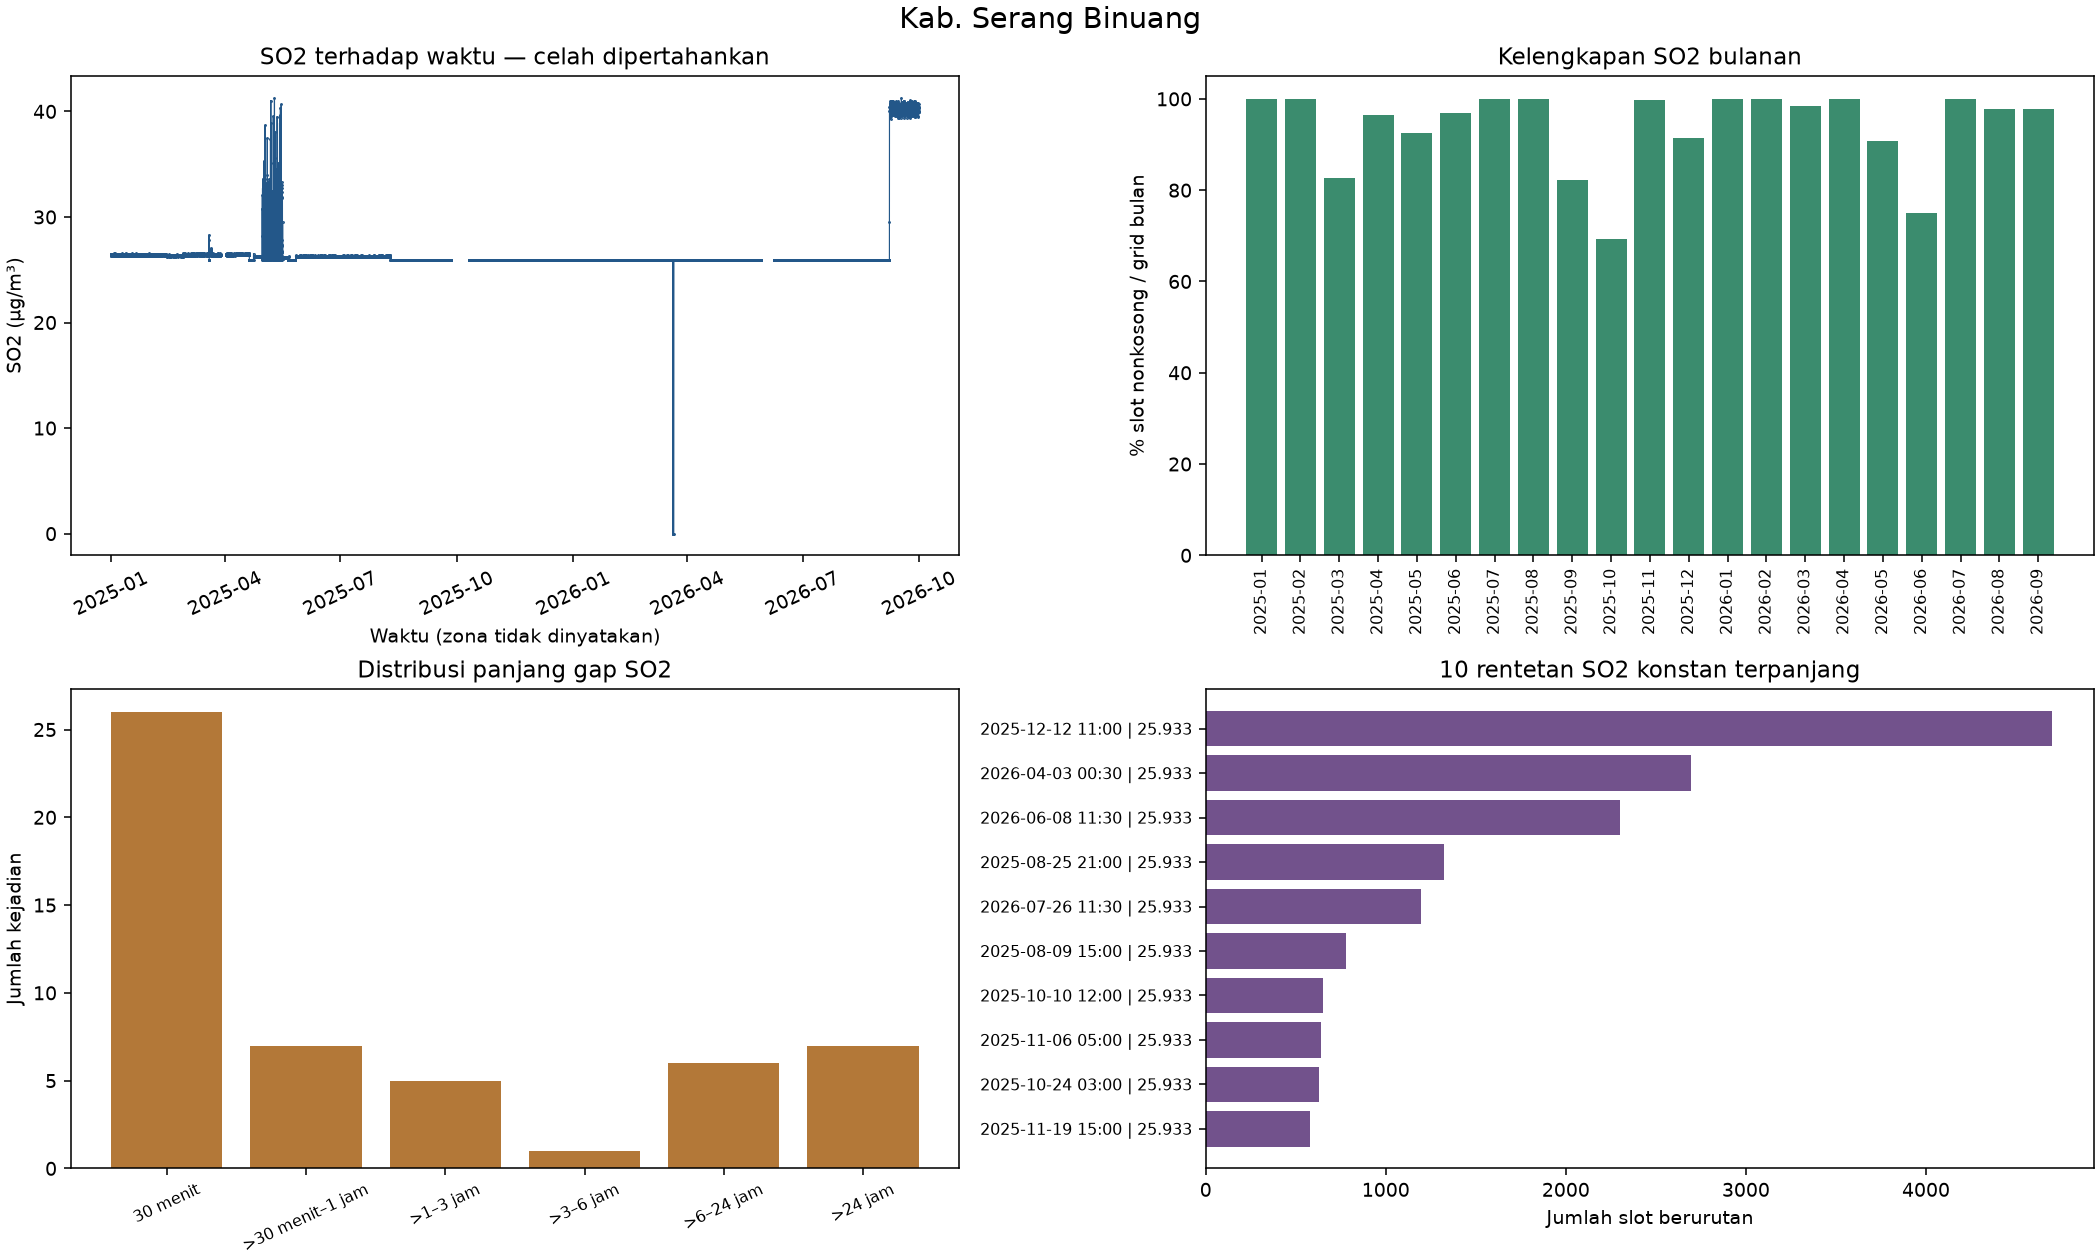

## Kab. Tangerang Curug

### Ringkasan

,File,Stasiun,Jumlah baris sumber,Timestamp minimum,Timestamp maksimum,Timestamp gagal,Waktu nonmenurun,Waktu meningkat ketat,Pasangan waktu mundur,Grup duplikat identik,Grup duplikat konflik,Baris dalam grup duplikat,Baris duplikat tambahan,Di luar pola 00 atau 30,Pasangan sumber terbaca,Pasangan sumber bukan 30 menit,Interval unik terurut bukan 30 menit,Denominator slot grid,SO2 teramati slot,SO2 teramati persen,Tanpa baris slot,Tanpa baris persen,Baris ada SO2 kosong slot,Baris ada SO2 kosong persen,SO2 hilang slot,SO2 hilang persen,Slot SO2 ambigu,Jumlah gap SO2,Gap terpanjang jam,SO2 nonkosong baris di luar grid
0,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Tangerang Curug,30137,2025-01-01,2026-09-30 17:30:00,0,True,True,0,0,0,0,0,4,30136,41,41,30612,30010,98.033451,479,1.564746,123,0.401803,602,1.966549,0,34,120.5,0


### Metadata

,File,Stasiun,Periode teks asli,Awal metadata,Akhir metadata,Tanggal aktual minimum,Tanggal aktual maksimum,Awal tanggal sesuai,Akhir tanggal sesuai,Baris di luar tanggal metadata,Keterbatasan
0,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Tangerang Curug,: 01 Januari 2025 - 30 September 2026,2025-01-01,2026-09-30,2025-01-01,2026-09-30,True,True,0,Tanggal tanpa jam; zona waktu dan kode sensor ...


### Kelengkapan variabel

... (21 outputs left out)

### Masalah_waktu: 4 kejadian (maksimal 10 ditampilkan)

,File,Stasiun,Jenis,Baris Excel,Nilai asli
0,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Tangerang Curug,di luar menit 00/30 atau detik bukan nol,3527,2025-03-20 11:01:00
1,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Tangerang Curug,di luar menit 00/30 atau detik bukan nol,3528,2025-03-20 13:03:00
2,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Tangerang Curug,di luar menit 00/30 atau detik bukan nol,3529,2025-03-20 17:03:00
3,Telkom University Purwokerto - Intan Azizah.xlsx,Kab. Tangerang Curug,di luar menit 00/30 atau detik bukan nol,3530,2025-03-20 20:01:00


### Nilai_nonnumerik: 0 kejadian (maksimal 10 ditampilkan)

""


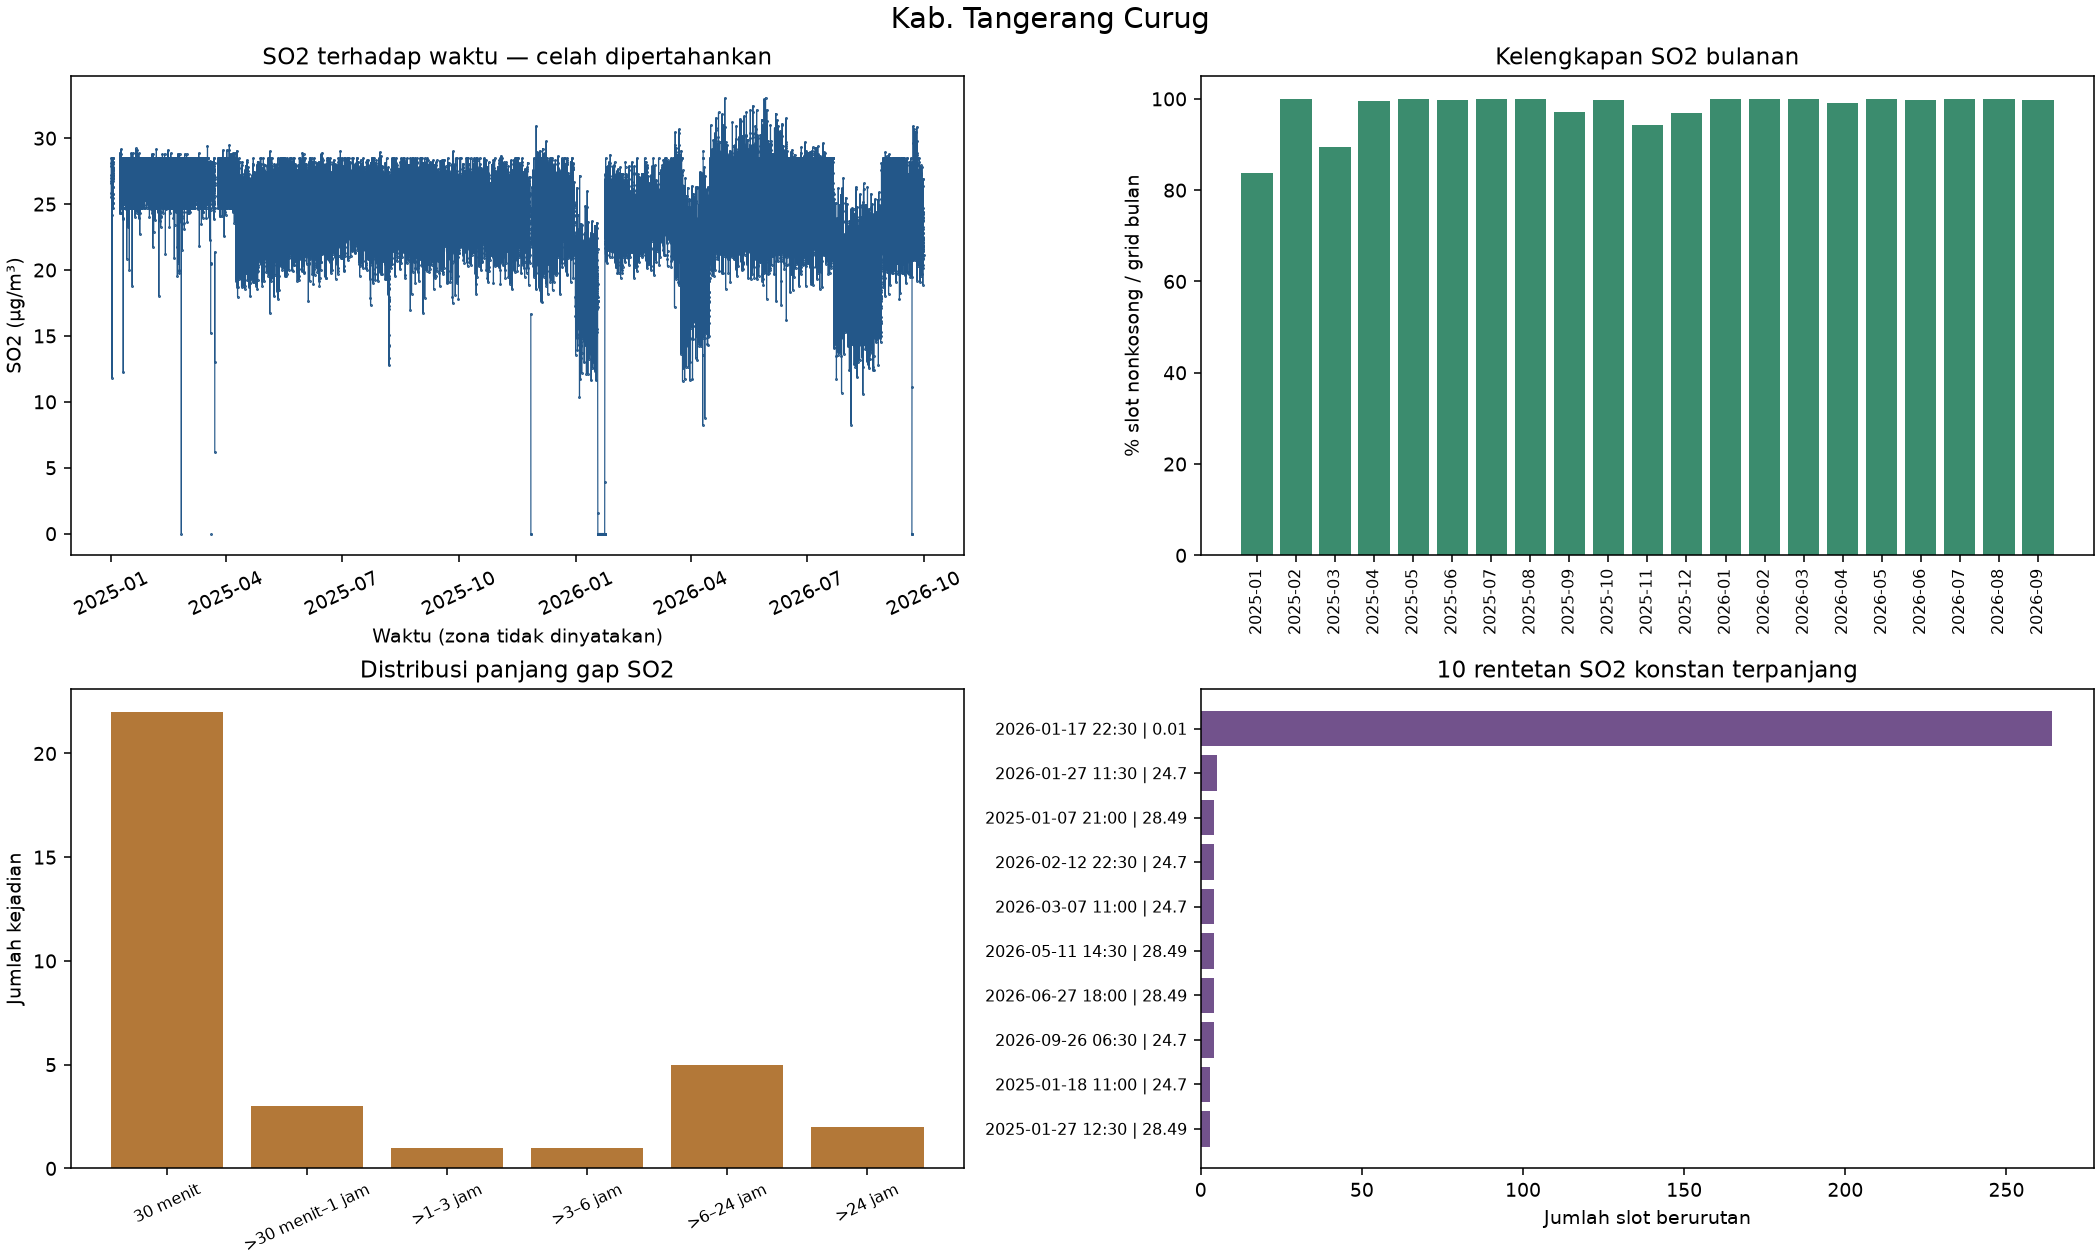

## Tangerang Pasir Jaya

### Ringkasan

,File,Stasiun,Jumlah baris sumber,Timestamp minimum,Timestamp maksimum,Timestamp gagal,Waktu nonmenurun,Waktu meningkat ketat,Pasangan waktu mundur,Grup duplikat identik,Grup duplikat konflik,Baris dalam grup duplikat,Baris duplikat tambahan,Di luar pola 00 atau 30,Pasangan sumber terbaca,Pasangan sumber bukan 30 menit,Interval unik terurut bukan 30 menit,Denominator slot grid,SO2 teramati slot,SO2 teramati persen,Tanpa baris slot,Tanpa baris persen,Baris ada SO2 kosong slot,Baris ada SO2 kosong persen,SO2 hilang slot,SO2 hilang persen,Slot SO2 ambigu,Jumlah gap SO2,Gap terpanjang jam,SO2 nonkosong baris di luar grid
0,Telkom University Purwokerto - Intan Azizah.xlsx,Tangerang Pasir Jaya,23674,2025-01-01,2026-09-30 17:30:00,0,True,True,0,0,0,0,0,0,23673,98,98,30612,3569,11.658827,6938,22.664315,20105,65.676859,27043,88.341173,0,53,5816.5,0


### Metadata

,File,Stasiun,Periode teks asli,Awal metadata,Akhir metadata,Tanggal aktual minimum,Tanggal aktual maksimum,Awal tanggal sesuai,Akhir tanggal sesuai,Baris di luar tanggal metadata,Keterbatasan
0,Telkom University Purwokerto - Intan Azizah.xlsx,Tangerang Pasir Jaya,: 01 Januari 2025 - 30 September 2026,2025-01-01,2026-09-30,2025-01-01,2026-09-30,True,True,0,Tanggal tanpa jam; zona waktu dan kode sensor ...


### Kelengkapan variabel

... (21 outputs left out)

### Masalah_waktu: 0 kejadian (maksimal 10 ditampilkan)

""


### Nilai_nonnumerik: 0 kejadian (maksimal 10 ditampilkan)

""


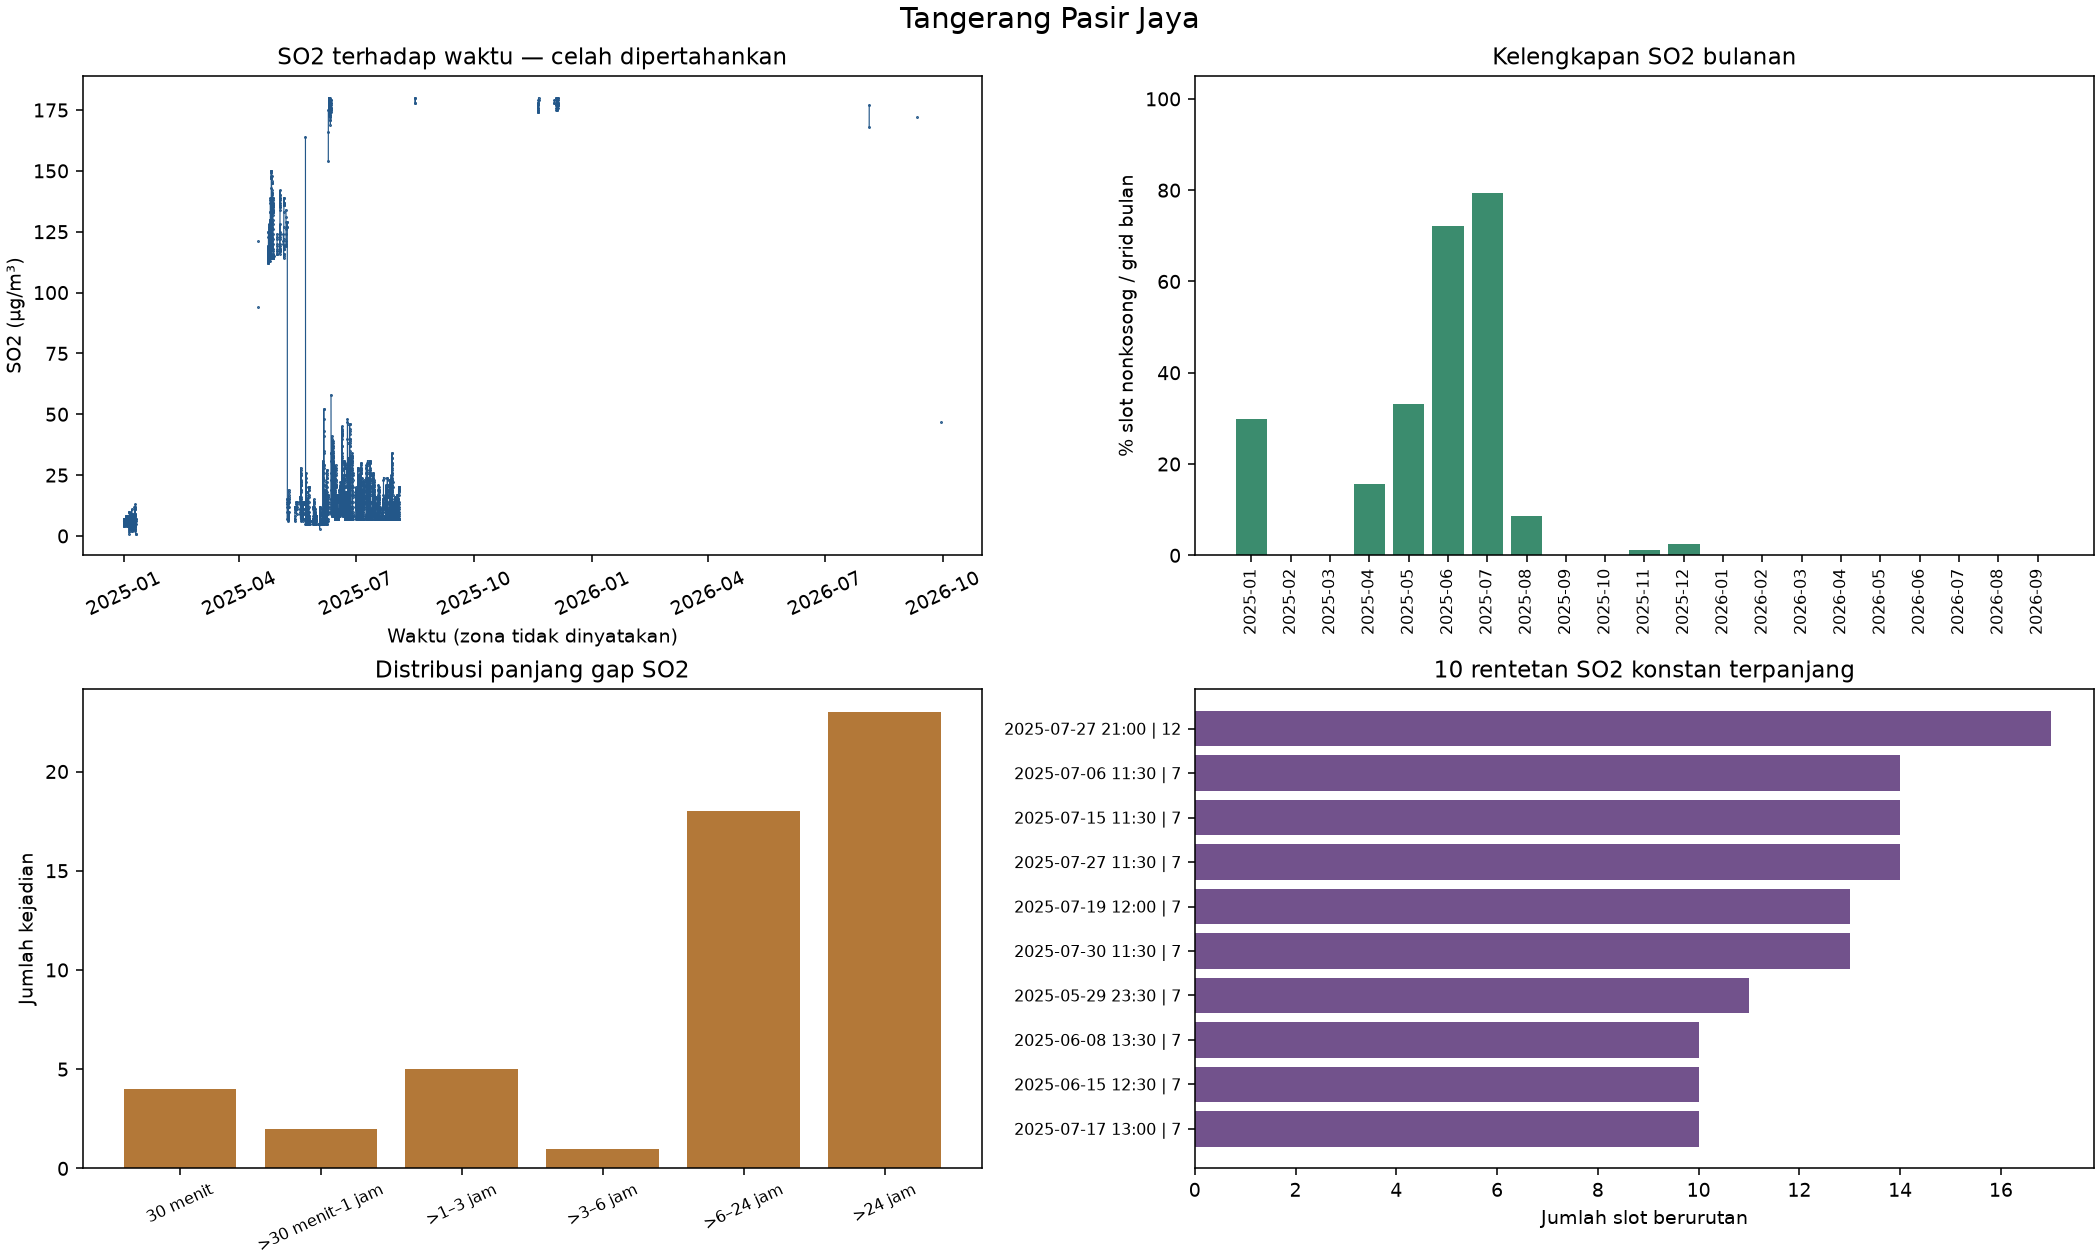

## Tangerang Selatan Serpong

### Ringkasan

,File,Stasiun,Jumlah baris sumber,Timestamp minimum,Timestamp maksimum,Timestamp gagal,Waktu nonmenurun,Waktu meningkat ketat,Pasangan waktu mundur,Grup duplikat identik,Grup duplikat konflik,Baris dalam grup duplikat,Baris duplikat tambahan,Di luar pola 00 atau 30,Pasangan sumber terbaca,Pasangan sumber bukan 30 menit,Interval unik terurut bukan 30 menit,Denominator slot grid,SO2 teramati slot,SO2 teramati persen,Tanpa baris slot,Tanpa baris persen,Baris ada SO2 kosong slot,Baris ada SO2 kosong persen,SO2 hilang slot,SO2 hilang persen,Slot SO2 ambigu,Jumlah gap SO2,Gap terpanjang jam,SO2 nonkosong baris di luar grid
0,Telkom University Purwokerto - Intan Azizah.xlsx,Tangerang Selatan Serpong,25080,2025-01-01,2026-09-30 17:30:00,0,True,True,0,0,0,0,0,0,25079,28,28,30612,14184,46.334771,5532,18.071345,10896,35.593885,16428,53.665229,0,222,2845.0,0


### Metadata

,File,Stasiun,Periode teks asli,Awal metadata,Akhir metadata,Tanggal aktual minimum,Tanggal aktual maksimum,Awal tanggal sesuai,Akhir tanggal sesuai,Baris di luar tanggal metadata,Keterbatasan
0,Telkom University Purwokerto - Intan Azizah.xlsx,Tangerang Selatan Serpong,: 01 Januari 2025 - 30 September 2026,2025-01-01,2026-09-30,2025-01-01,2026-09-30,True,True,0,Tanggal tanpa jam; zona waktu dan kode sensor ...


### Kelengkapan variabel

... (21 outputs left out)

### Masalah_waktu: 0 kejadian (maksimal 10 ditampilkan)

""


### Nilai_nonnumerik: 0 kejadian (maksimal 10 ditampilkan)

""


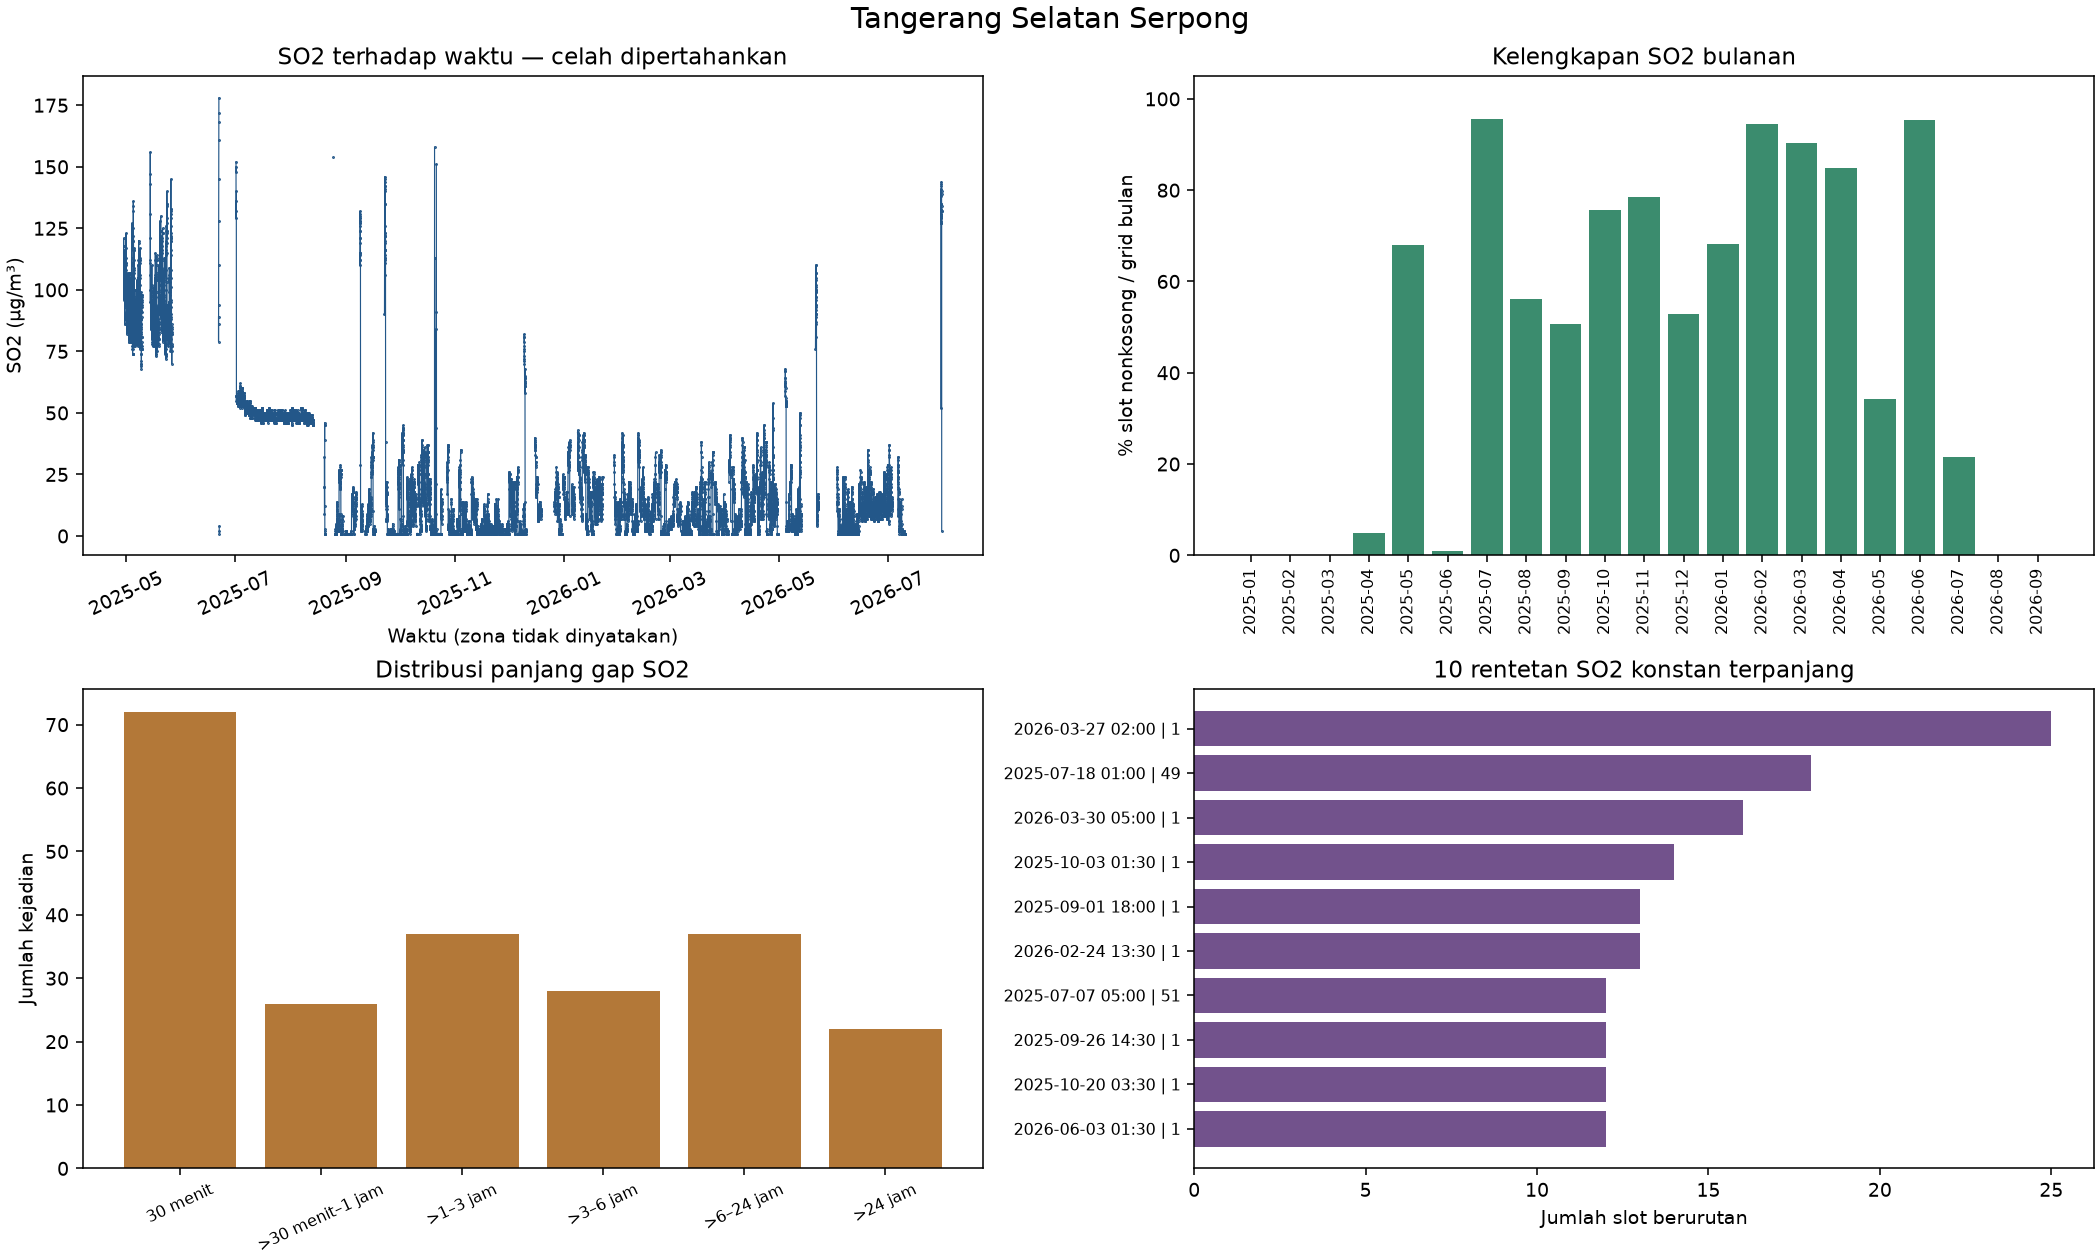

## Serang Sumurpecung

### Ringkasan

,File,Stasiun,Jumlah baris sumber,Timestamp minimum,Timestamp maksimum,Timestamp gagal,Waktu nonmenurun,Waktu meningkat ketat,Pasangan waktu mundur,Grup duplikat identik,Grup duplikat konflik,Baris dalam grup duplikat,Baris duplikat tambahan,Di luar pola 00 atau 30,Pasangan sumber terbaca,Pasangan sumber bukan 30 menit,Interval unik terurut bukan 30 menit,Denominator slot grid,SO2 teramati slot,SO2 teramati persen,Tanpa baris slot,Tanpa baris persen,Baris ada SO2 kosong slot,Baris ada SO2 kosong persen,SO2 hilang slot,SO2 hilang persen,Slot SO2 ambigu,Jumlah gap SO2,Gap terpanjang jam,SO2 nonkosong baris di luar grid
0,Telkom University Purwokerto - Intan Azizah.xlsx,Serang Sumurpecung,25444,2025-01-01,2026-09-19 10:30:00,0,True,True,0,0,0,0,0,0,25443,818,818,30070,23711,78.852677,4626,15.384104,1733,5.763219,6359,21.147323,0,796,527.0,0


### Metadata

,File,Stasiun,Periode teks asli,Awal metadata,Akhir metadata,Tanggal aktual minimum,Tanggal aktual maksimum,Awal tanggal sesuai,Akhir tanggal sesuai,Baris di luar tanggal metadata,Keterbatasan
0,Telkom University Purwokerto - Intan Azizah.xlsx,Serang Sumurpecung,: 01 Januari 2025 - 19 September 2026,2025-01-01,2026-09-19,2025-01-01,2026-09-19,True,True,0,Tanggal tanpa jam; zona waktu dan kode sensor ...


### Kelengkapan variabel

... (21 outputs left out)

### Masalah_waktu: 0 kejadian (maksimal 10 ditampilkan)

""


### Nilai_nonnumerik: 0 kejadian (maksimal 10 ditampilkan)

""


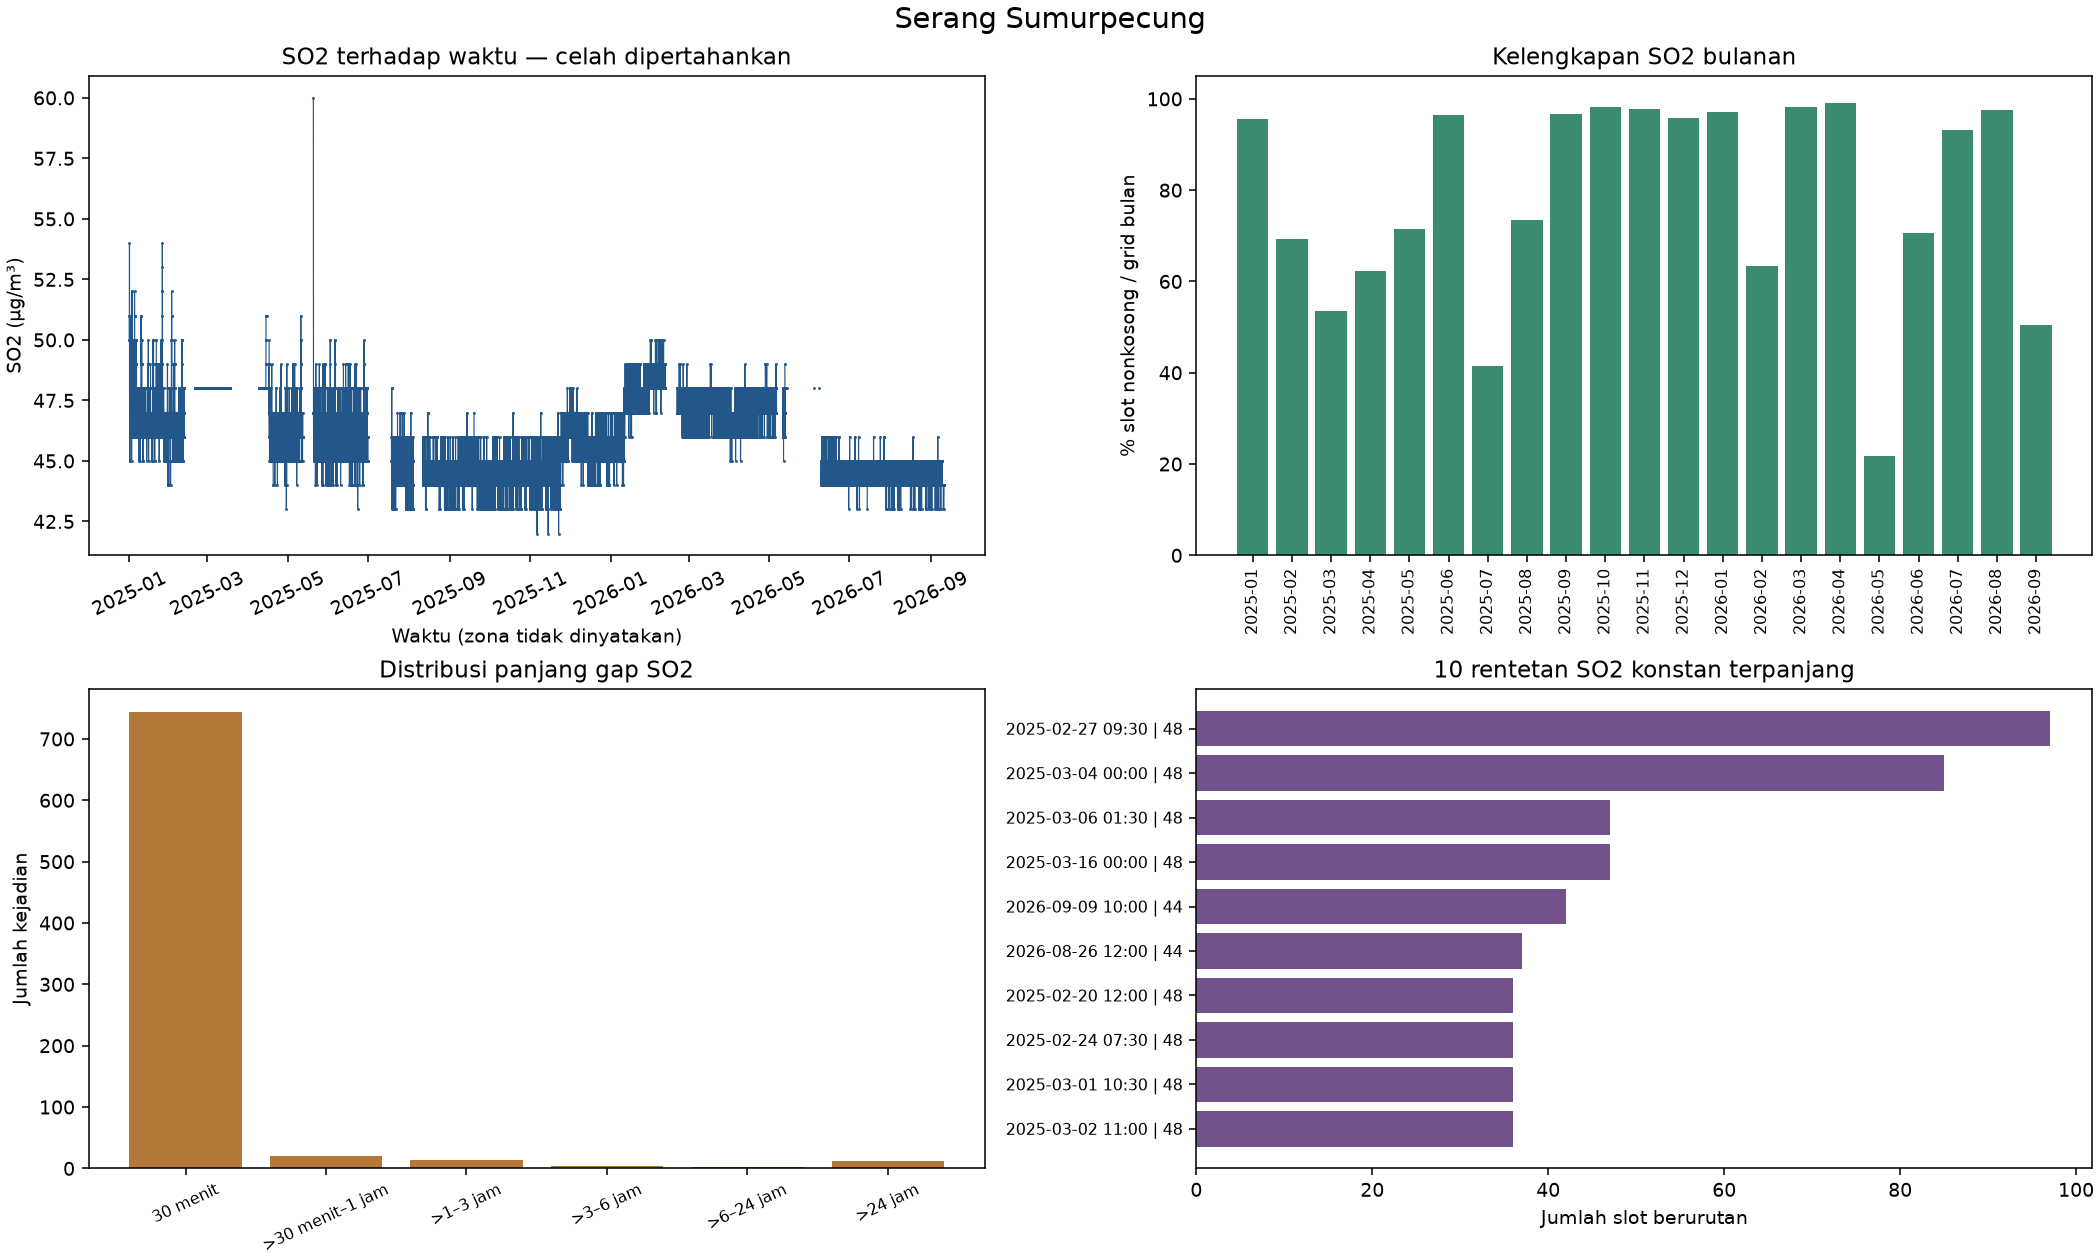

In [3]:
for result in results:
    station = result['summary']['Stasiun']
    display(Markdown(f'## {station}'))
    for title in ['Ringkasan','Metadata','Kelengkapan_variabel','SO2_bulanan',
                  'Kelompok_gap','Statistik_nilai','Ringkas_konstan',
                  'Aturan_pemeriksaan','Contoh_pemeriksaan','Kandidat_ekstrem']:
        display(Markdown(f'### {title.replace("_"," ")}'))
        display(pd.DataFrame([r for r in tables.get(title,[]) if r.get('Stasiun')==station]))
    display(Markdown('### Gap SO2 — 10 terpanjang; daftar lengkap pada workbook'))
    display(pd.DataFrame(sorted(result['gaps'],key=lambda g:-g['Slot hilang'])[:10]))
    display(Markdown('### 10 rentetan SO2 konstan terpanjang'))
    display(pd.DataFrame(result['top_runs']))
    for title in ['Duplikat','Masalah_waktu','Nilai_nonnumerik']:
        subset=[r for r in tables.get(title,[]) if r.get('Stasiun')==station]
        display(Markdown(f'### {title}: {len(subset)} kejadian (maksimal 10 ditampilkan)'))
        display(pd.DataFrame(subset[:10]))
    display(Image(filename=str(result['figure'])))

## Ekspor tabel audit

Workbook ditulis oleh runtime artifact-tool; analisis Python disampaikan sebagai JSON
perantara. Timestamp pada workbook berupa tanggal Excel tanpa asumsi zona waktu.
Tabel seluruh stasiun memiliki kolom `Stasiun` agar dapat difilter, tanpa penggabungan
seri antarstasiun. File CSV grid hanya untuk audit di `outputs/audit_grids/`.


In [4]:
export_excel()
print('Workbook:', ROOT/'outputs'/'audit_kualitas_data.xlsx')
print('Grafik:', ROOT/'outputs'/'figures')
print('Ringkasan:', ROOT/'outputs'/'ringkasan_audit_kualitas.md')

{"kind":"table","sheet":"Ringkasan","address":"A1:F4","rows":4,"cols":6,"values":[["File","Stasiun","Jumlah baris sumber","Timestamp minimum","Timestamp maksimum","Timestamp gagal"],["Telkom University Purwokerto - Intan Azizah.xlsx","Bandar Lampung Talang",28226,45658,46287.47916666667,0],["Telkom University Purwokerto - Intan Azizah.xlsx","Kab. Lampung Selatan Way Urang",29966,45658,46286.54166666667,0],["Telkom University Purwokerto - Intan Azizah.xlsx","Kota Cilegon Pulomerak",30399,45658,46295.72916666667,0]]}
Inspect result written to file: C:\Users\INTAN\airpollutan_SO2\outputs\audit_kualitas_data.xlsx.inspect.ndjson
Ekspor selesai: 20 sheet.

Workbook: C:\Users\INTAN\airpollutan_SO2\outputs\audit_kualitas_data.xlsx
Grafik: C:\Users\INTAN\airpollutan_SO2\outputs\figures
Ringkasan: C:\Users\INTAN\airpollutan_SO2\outputs\ringkasan_audit_kualitas.md


## Temuan, keterbatasan, dan implikasi eksperimen

Persentase teramati belum menyatakan validitas. Kelompok panjang gap hanya deskriptif.
Keputusan preprocessing, interpretasi kode, dan validasi sensor memerlukan bukti tambahan.


In [5]:
display(Markdown((ROOT/'outputs'/'ringkasan_audit_kualitas.md').read_text(encoding='utf-8').replace('(figures/', '(../outputs/figures/')))

# Ringkasan audit kualitas data SO₂

Audit terpisah untuk setiap stasiun, mengacu struktur notebook 01. File sumber dibaca tanpa modifikasi. Tidak dilakukan imputasi, penghapusan outlier, smoothing, scaling, pemilihan stasiun final atau pelatihan model.

## Definisi dan denominator

- **Sumber:** Excel asli pada data_raw; struktur mengacu notebook 01 dan audit_struktur_data.json. Sumber dibaca read_only, tidak disimpan ulang.
- **Persen kosong variabel:** 100 × jumlah sel kosong / seluruh baris tabel stasiun (termasuk timestamp gagal dan duplikat). Kosong = None, NaN, atau teks hanya whitespace; nol bukan kosong.
- **Grid audit:** Slot menit 00/30 dengan detik dan mikrodetik nol dalam [timestamp minimum, maksimum]. Tidak membulatkan timestamp di luar pola; slot di luar pola dilaporkan terpisah.
- **Persen SO2 teramati:** 100 × slot grid dengan sedikitnya satu nilai SO2 nonkosong / seluruh slot grid. Nonkosong tidak otomatis valid; teks, nol, negatif, ekstrem dan duplikat bertentangan tetap dapat dihitung teramati.
- **Persen tanpa baris:** 100 × slot grid tanpa baris sumber / seluruh slot grid.
- **Persen baris ada SO2 kosong:** 100 × slot grid dengan baris tetapi semua SO2 kosong / seluruh slot grid.
- **Persen hilang SO2:** 100 × (slot tanpa baris + slot baris ada semua SO2 kosong) / seluruh slot grid.
- **Persen bulanan:** Definisi kelengkapan SO2 yang sama, denominator slot grid dalam bulan tersebut; bulan awal/akhir dapat parsial.
- **Duplikat:** Grup berdasarkan timestamp berhasil dibaca; identik jika seluruh 13 nilai pengukuran sama termasuk pola kosong dan tipe Python. Konflik bila ada perbedaan. Baris tambahan = jumlah baris grup − 1; tidak ada baris dihapus.
- **Plot dan konstan:** Slot numerik hanya jika SO2 semua baris pada timestamp setuju dan tidak kosong/nonnumerik/nonfinite. Konflik SO2, sel kosong, atau slot hilang memutus garis dan rentetan. Duplikat SO2 identik ditampilkan sekali hanya pada grid audit.
- **Rentetan konstan:** Kesamaan numerik tepat (tanpa toleransi), minimal 2 slot 30 menit berurutan. Jumlah slot dan rentang akhir−awal dilaporkan terpisah. Per variabel, kosong/konflik/nonnumerik memutus rentetan.
- **Gap SO2:** Rentetan slot grid tanpa SO2 nonkosong. Durasi = jumlah slot × 30 menit; bukan akhir−awal. Satu slot berdurasi 30 menit.
- **Posisi gap:** Sebelum slot SO2 teramati pertama; setelah slot teramati terakhir; tengah seri; atau seluruh seri jika tidak ada SO2 teramati.
- **Kelompok gap:** 30 menit; >30 menit–1 jam; >1–3 jam; >3–6 jam; >6–24 jam; >24 jam. Kelompok deskriptif, bukan batas imputasi.
- **Statistik nilai:** Dihitung per baris sumber dari nilai yang dapat direpresentasikan numerik dan finite; tidak mengganti kolom sumber. Teks numerik dihitung setelah parsing sementara dan dilaporkan tipenya. Jumlah numerik bukan jumlah valid.
- **Nol dan negatif:** Jumlah di antara nilai numerik finite per baris sumber. Tidak dihapus dan tidak diasumsikan salah.
- **Kandidat ekstrem:** Contoh nilai minimum/maksimum setiap variabel, bukan keputusan outlier atau batas sensor.
- **Metadata:** Tanggal laporan tanpa jam dibandingkan secara tanggal kalender; akhir hari inklusif. Zona waktu, kode sensor, ambang sensor dan penyebab anomali tidak disimpulkan.
- **Interval sumber:** Selisih dua baris bertetangga pada urutan asli hanya jika keduanya berhasil dibaca. Timestamp gagal memutus pasangan. Interval unik terurut dihitung terpisah, tanpa mengubah sumber.
- **Persentase lain:** Tidak ada persentase lain selain denominator eksplisit pada tabel dan definisi di atas. Angka 0–100 adalah persen, bukan fraksi Excel.

## Ringkasan per stasiun

| Stasiun | Baris sumber | Slot grid | SO2 teramati slot | Teramati (%) | Tanpa baris | Baris ada, SO2 kosong | Gap terpanjang (jam) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Bandar Lampung Talang | 28226 | 30216 | 26189 | 86.67 | 1990 | 2037 | 1011.5 |
| Kab. Lampung Selatan Way Urang | 29966 | 30171 | 28246 | 93.62 | 206 | 1719 | 490.5 |
| Kota Cilegon Pulomerak | 30399 | 30612 | 25439 | 83.10 | 215 | 4958 | 675 |
| Kab. Serang Binuang | 28732 | 30612 | 28721 | 93.82 | 1886 | 5 | 331 |
| Kab. Tangerang Curug | 30137 | 30612 | 30010 | 98.03 | 479 | 123 | 120.5 |
| Tangerang Pasir Jaya | 23674 | 30612 | 3569 | 11.66 | 6938 | 20105 | 5816.5 |
| Tangerang Selatan Serpong | 25080 | 30612 | 14184 | 46.33 | 5532 | 10896 | 2845 |
| Serang Sumurpecung | 25444 | 30070 | 23711 | 78.85 | 4626 | 1733 | 527 |

### Bandar Lampung Talang

- Waktu aktual: 2025-01-01 00:00:00 sampai 2026-09-22 11:30:00. Urutan nonmenurun: True; meningkat ketat: True.
- Timestamp gagal: 0; grup duplikat identik: 0; konflik: 0; baris tambahan duplikat: 0.
- Di luar pola 00/30: 0; pasangan sumber bukan 30 menit: 29 dari 28225 pasangan terbaca.
- SO2 hilang: 4027 slot (13.33% dari 30216 slot); 32 kejadian. SO2 ambigu pada duplikat: 0 slot.
- Metadata periode: `: 01 Januari 2025 - 22 September 2026`. Awal tanggal sesuai: True; akhir tanggal sesuai: True; baris di luar tanggal metadata: 0.
- Posisi gap (jumlah kejadian): tengah seri: 31, setelah pengamatan terakhir: 1.
- Gap terpanjang: 2026-08-11 08:30:00 sampai 2026-09-22 11:30:00; 2023 slot × 30 menit = 1011.5 jam (setelah pengamatan terakhir).
- Rentetan SO2 konstan terpanjang: 61 µg/m³; 3190 slot, 2025-09-26 02:30:00 sampai 2025-12-01 13:00:00. Belum dinyatakan sebagai kesalahan.
- Pemeriksaan rentang: Kelembaban di luar 0–100%: 0 baris; Arah Angin di luar 0–360 derajat: 0 baris; Kec.Angin negatif: 0 baris.
- Nilai nonnumerik/nonfinite pada kolom pengukuran: 0 sel. Tipe asli, statistik, nol dan negatif tersedia pada tabel Excel.

![Audit Bandar Lampung Talang](../outputs/figures/01_audit_so2.png)

### Kab. Lampung Selatan Way Urang

- Waktu aktual: 2025-01-01 00:00:00 sampai 2026-09-21 13:00:00. Urutan nonmenurun: True; meningkat ketat: True.
- Timestamp gagal: 0; grup duplikat identik: 0; konflik: 0; baris tambahan duplikat: 0.
- Di luar pola 00/30: 1; pasangan sumber bukan 30 menit: 22 dari 29965 pasangan terbaca.
- SO2 hilang: 1925 slot (6.38% dari 30171 slot); 29 kejadian. SO2 ambigu pada duplikat: 0 slot.
- Metadata periode: `: 01 Januari 2025 - 21 September 2026`. Awal tanggal sesuai: True; akhir tanggal sesuai: True; baris di luar tanggal metadata: 0.
- Posisi gap (jumlah kejadian): sebelum pengamatan pertama: 1, tengah seri: 28.
- Gap terpanjang: 2025-01-24 08:30:00 sampai 2025-02-13 18:30:00; 981 slot × 30 menit = 490.5 jam (tengah seri).
- Rentetan SO2 konstan terpanjang: 1.69 µg/m³; 16 slot, 2025-07-02 03:00:00 sampai 2025-07-02 10:30:00. Belum dinyatakan sebagai kesalahan.
- Pemeriksaan rentang: Kelembaban di luar 0–100%: 0 baris; Arah Angin di luar 0–360 derajat: 0 baris; Kec.Angin negatif: 0 baris.
- Nilai nonnumerik/nonfinite pada kolom pengukuran: 0 sel. Tipe asli, statistik, nol dan negatif tersedia pada tabel Excel.

![Audit Kab. Lampung Selatan Way Urang](../outputs/figures/02_audit_so2.png)

### Kota Cilegon Pulomerak

- Waktu aktual: 2025-01-01 00:00:00 sampai 2026-09-30 17:30:00. Urutan nonmenurun: True; meningkat ketat: True.
- Timestamp gagal: 0; grup duplikat identik: 0; konflik: 0; baris tambahan duplikat: 0.
- Di luar pola 00/30: 2; pasangan sumber bukan 30 menit: 46 dari 30398 pasangan terbaca.
- SO2 hilang: 5173 slot (16.90% dari 30612 slot); 51 kejadian. SO2 ambigu pada duplikat: 0 slot.
- Metadata periode: `: 01 Januari 2025 - 30 September 2026`. Awal tanggal sesuai: True; akhir tanggal sesuai: True; baris di luar tanggal metadata: 0.
- Posisi gap (jumlah kejadian): tengah seri: 51.
- Gap terpanjang: 2026-06-27 05:00:00 sampai 2026-07-25 07:30:00; 1350 slot × 30 menit = 675 jam (tengah seri).
- Rentetan SO2 konstan terpanjang: 30.26 µg/m³; 1362 slot, 2025-02-06 05:30:00 sampai 2025-03-06 14:00:00. Belum dinyatakan sebagai kesalahan.
- Pemeriksaan rentang: Kelembaban di luar 0–100%: 0 baris; Arah Angin di luar 0–360 derajat: 0 baris; Kec.Angin negatif: 0 baris.
- Nilai nonnumerik/nonfinite pada kolom pengukuran: 0 sel. Tipe asli, statistik, nol dan negatif tersedia pada tabel Excel.

![Audit Kota Cilegon Pulomerak](../outputs/figures/03_audit_so2.png)

### Kab. Serang Binuang

- Waktu aktual: 2025-01-01 00:00:00 sampai 2026-09-30 17:30:00. Urutan nonmenurun: True; meningkat ketat: True.
- Timestamp gagal: 0; grup duplikat identik: 0; konflik: 0; baris tambahan duplikat: 0.
- Di luar pola 00/30: 6; pasangan sumber bukan 30 menit: 60 dari 28731 pasangan terbaca.
- SO2 hilang: 1891 slot (6.18% dari 30612 slot); 52 kejadian. SO2 ambigu pada duplikat: 0 slot.
- Metadata periode: `: 01 Januari 2025 - 30 September 2026`. Awal tanggal sesuai: True; akhir tanggal sesuai: True; baris di luar tanggal metadata: 0.
- Posisi gap (jumlah kejadian): tengah seri: 52.
- Gap terpanjang: 2025-09-26 17:00:00 sampai 2025-10-10 11:30:00; 662 slot × 30 menit = 331 jam (tengah seri).
- Rentetan SO2 konstan terpanjang: 25.933 µg/m³; 4699 slot, 2025-12-12 11:00:00 sampai 2026-03-20 08:00:00. Belum dinyatakan sebagai kesalahan.
- Pemeriksaan rentang: Kelembaban di luar 0–100%: 259 baris; Arah Angin di luar 0–360 derajat: 43 baris; Kec.Angin negatif: 0 baris.
- Nilai nonnumerik/nonfinite pada kolom pengukuran: 0 sel. Tipe asli, statistik, nol dan negatif tersedia pada tabel Excel.

![Audit Kab. Serang Binuang](../outputs/figures/04_audit_so2.png)

### Kab. Tangerang Curug

- Waktu aktual: 2025-01-01 00:00:00 sampai 2026-09-30 17:30:00. Urutan nonmenurun: True; meningkat ketat: True.
- Timestamp gagal: 0; grup duplikat identik: 0; konflik: 0; baris tambahan duplikat: 0.
- Di luar pola 00/30: 4; pasangan sumber bukan 30 menit: 41 dari 30136 pasangan terbaca.
- SO2 hilang: 602 slot (1.97% dari 30612 slot); 34 kejadian. SO2 ambigu pada duplikat: 0 slot.
- Metadata periode: `: 01 Januari 2025 - 30 September 2026`. Awal tanggal sesuai: True; akhir tanggal sesuai: True; baris di luar tanggal metadata: 0.
- Posisi gap (jumlah kejadian): tengah seri: 34.
- Gap terpanjang: 2025-01-02 14:00:00 sampai 2025-01-07 14:00:00; 241 slot × 30 menit = 120.5 jam (tengah seri).
- Rentetan SO2 konstan terpanjang: 0.01 µg/m³; 264 slot, 2026-01-17 22:30:00 sampai 2026-01-23 10:00:00. Belum dinyatakan sebagai kesalahan.
- Pemeriksaan rentang: Kelembaban di luar 0–100%: 0 baris; Arah Angin di luar 0–360 derajat: 30 baris; Kec.Angin negatif: 0 baris.
- Nilai nonnumerik/nonfinite pada kolom pengukuran: 0 sel. Tipe asli, statistik, nol dan negatif tersedia pada tabel Excel.

![Audit Kab. Tangerang Curug](../outputs/figures/05_audit_so2.png)

### Tangerang Pasir Jaya

- Waktu aktual: 2025-01-01 00:00:00 sampai 2026-09-30 17:30:00. Urutan nonmenurun: True; meningkat ketat: True.
- Timestamp gagal: 0; grup duplikat identik: 0; konflik: 0; baris tambahan duplikat: 0.
- Di luar pola 00/30: 0; pasangan sumber bukan 30 menit: 98 dari 23673 pasangan terbaca.
- SO2 hilang: 27043 slot (88.34% dari 30612 slot); 53 kejadian. SO2 ambigu pada duplikat: 0 slot.
- Metadata periode: `: 01 Januari 2025 - 30 September 2026`. Awal tanggal sesuai: True; akhir tanggal sesuai: True; baris di luar tanggal metadata: 0.
- Posisi gap (jumlah kejadian): tengah seri: 52, setelah pengamatan terakhir: 1.
- Gap terpanjang: 2025-12-05 02:30:00 sampai 2026-08-04 10:30:00; 11633 slot × 30 menit = 5816.5 jam (tengah seri).
- Rentetan SO2 konstan terpanjang: 12 µg/m³; 17 slot, 2025-07-27 21:00:00 sampai 2025-07-28 05:00:00. Belum dinyatakan sebagai kesalahan.
- Pemeriksaan rentang: Kelembaban di luar 0–100%: 185 baris; Arah Angin di luar 0–360 derajat: 185 baris; Kec.Angin negatif: 0 baris.
- Nilai nonnumerik/nonfinite pada kolom pengukuran: 0 sel. Tipe asli, statistik, nol dan negatif tersedia pada tabel Excel.

![Audit Tangerang Pasir Jaya](../outputs/figures/06_audit_so2.png)

### Tangerang Selatan Serpong

- Waktu aktual: 2025-01-01 00:00:00 sampai 2026-09-30 17:30:00. Urutan nonmenurun: True; meningkat ketat: True.
- Timestamp gagal: 0; grup duplikat identik: 0; konflik: 0; baris tambahan duplikat: 0.
- Di luar pola 00/30: 0; pasangan sumber bukan 30 menit: 28 dari 25079 pasangan terbaca.
- SO2 hilang: 16428 slot (53.67% dari 30612 slot); 222 kejadian. SO2 ambigu pada duplikat: 0 slot.
- Metadata periode: `: 01 Januari 2025 - 30 September 2026`. Awal tanggal sesuai: True; akhir tanggal sesuai: True; baris di luar tanggal metadata: 0.
- Posisi gap (jumlah kejadian): sebelum pengamatan pertama: 1, tengah seri: 220, setelah pengamatan terakhir: 1.
- Gap terpanjang: 2025-01-01 00:00:00 sampai 2025-04-29 12:30:00; 5690 slot × 30 menit = 2845 jam (sebelum pengamatan pertama).
- Rentetan SO2 konstan terpanjang: 1 µg/m³; 25 slot, 2026-03-27 02:00:00 sampai 2026-03-27 14:00:00. Belum dinyatakan sebagai kesalahan.
- Pemeriksaan rentang: Kelembaban di luar 0–100%: 3 baris; Arah Angin di luar 0–360 derajat: 3 baris; Kec.Angin negatif: 0 baris.
- Nilai nonnumerik/nonfinite pada kolom pengukuran: 0 sel. Tipe asli, statistik, nol dan negatif tersedia pada tabel Excel.

![Audit Tangerang Selatan Serpong](../outputs/figures/07_audit_so2.png)

### Serang Sumurpecung

- Waktu aktual: 2025-01-01 00:00:00 sampai 2026-09-19 10:30:00. Urutan nonmenurun: True; meningkat ketat: True.
- Timestamp gagal: 0; grup duplikat identik: 0; konflik: 0; baris tambahan duplikat: 0.
- Di luar pola 00/30: 0; pasangan sumber bukan 30 menit: 818 dari 25443 pasangan terbaca.
- SO2 hilang: 6359 slot (21.15% dari 30070 slot); 796 kejadian. SO2 ambigu pada duplikat: 0 slot.
- Metadata periode: `: 01 Januari 2025 - 19 September 2026`. Awal tanggal sesuai: True; akhir tanggal sesuai: True; baris di luar tanggal metadata: 0.
- Posisi gap (jumlah kejadian): tengah seri: 795, setelah pengamatan terakhir: 1.
- Gap terpanjang: 2025-03-18 11:30:00 sampai 2025-04-09 10:00:00; 1054 slot × 30 menit = 527 jam (tengah seri).
- Rentetan SO2 konstan terpanjang: 48 µg/m³; 97 slot, 2025-02-27 09:30:00 sampai 2025-03-01 09:30:00. Belum dinyatakan sebagai kesalahan.
- Pemeriksaan rentang: Kelembaban di luar 0–100%: 0 baris; Arah Angin di luar 0–360 derajat: 0 baris; Kec.Angin negatif: 0 baris.
- Nilai nonnumerik/nonfinite pada kolom pengukuran: 0 sel. Tipe asli, statistik, nol dan negatif tersedia pada tabel Excel.

![Audit Serang Sumurpecung](../outputs/figures/08_audit_so2.png)

## Keterbatasan dan implikasi rancangan eksperimen

- Tanggal metadata tidak menjelaskan jam, zona waktu, status sensor, kode khusus, batas deteksi atau batas sensor. Kesesuaian tanggal tidak menjamin seri lengkap.
- Grid mencakup minimum sampai maksimum timestamp tiap stasiun, bukan sebelum/di luar cakupan tersebut. Kelengkapan antarstasiun memiliki denominator periode yang berbeda; bulan tepi dapat parsial.
- Timestamp di luar pola 00/30 tidak dipindahkan ke grid. Jika ada, bandingkan hasil grid dengan observasi di luar grid sebelum merancang preprocessing.
- Sel nonkosong adalah teramati, belum otomatis valid. Nol, pengulangan dan SO2 tinggi belum membuktikan kesalahan. Nilai ekstrem minimum/maksimum ditampilkan sebagai kandidat pemeriksaan tanpa batas sensor rekaan.
- Statistik per baris mempertahankan duplikat, sedangkan kelengkapan grid menghitung satu slot per timestamp. Konflik duplikat harus diselesaikan berdasarkan bukti sebelum eksperimen; audit tidak memilih nilai sumber.
- Bandingkan eksperimen berdasarkan panjang dan posisi gap; kelompok gap hanya deskriptif. Gap panjang/pada tepi perlu dipertimbangkan terpisah dari gap pendek di tengah, tanpa menetapkan metode imputasi sekarang.
- Pemisahan train/validasi/test kelak harus kronologis. Rancang estimasi parameter preprocessing hanya dari train dan evaluasi kehilangan sintetis hanya pada observasi yang telah diverifikasi, agar tidak terjadi kebocoran.
- Rentetan konstan, lonjakan, dan rentang meteorologi perlu ditelusuri dengan dokumentasi/penyedia data. Tidak ada dugaan zona waktu, penyebab anomali, atau kaitan dengan aktivitas Anak Krakatau.
- Grafik tidak menghubungkan titik melalui nilai kosong, baris hilang atau SO2 ambigu/nonnumerik. Grid CSV disimpan di outputs/audit_grids khusus audit dan tidak menggantikan file mentah.

## Kendala

- Tidak ada pemeriksaan yang gagal dijalankan.

## Integritas sumber

- File: `data_raw\Telkom University Purwokerto - Intan Azizah.xlsx`
- SHA256 sebelum: `bd00734b954e8df024c048575fad07f1eb1cbe1083d4c8929ae362aeb45a7406`
- SHA256 sesudah: `bd00734b954e8df024c048575fad07f1eb1cbe1083d4c8929ae362aeb45a7406`
- Identik selama audit: True; identik dengan tahap 1: True.
